# Conectando meu drive com os dados e Bibliotecas


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("emmarex/plantdisease")

print("Path to dataset files:", path)

path

Using Colab cache for faster access to the 'plantdisease' dataset.
Path to dataset files: /kaggle/input/plantdisease


'/kaggle/input/plantdisease'

In [2]:
#Todas as bibliotecas do projeto estão instaladas no ambiente do Colab.
# 1. Instalar dependências necessárias para o servidor FastAPI
!pip install fastapi uvicorn python-multipart nest-asyncio pyngrok
!pip install ultralytics


from tensorflow.keras import layers, models, regularizers
from sklearn.metrics import classification_report, confusion_matrix
from fastapi import FastAPI, File, UploadFile, HTTPException
from fastapi.responses import JSONResponse
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from ultralytics import YOLO
from pathlib import Path
import tensorflow as tf
import seaborn as sns
import numpy as np
import pandas as pd
import zipfile
import cv2
import random
import os
import shutil
import glob
import time
import json
import ultralytics
import io


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Plotando a imagem do Dataset

Utilizando imagens do fallback (Kaggle): /kaggle/input/plantdisease/PlantVillage
Total de imagens disponíveis para sorteio: 20638


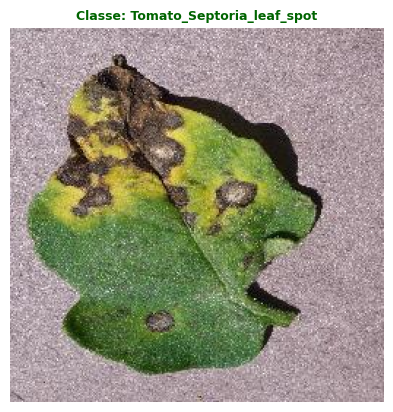

['/kaggle/input/plantdisease/PlantVillage/Tomato_Septoria_leaf_spot/e7eabac8-f9ff-4ec1-b07b-c11791b47bda___Matt.S_CG 1677.JPG']

In [3]:
# Caminhos possíveis
caminho_usuario = "/home/delmar/Downloads/data_folhas/PlantVillage"
caminho_alternativo = "/kaggle/input/plantdisease/PlantVillage"

pasta_ativa = ""


if os.path.exists(caminho_usuario) and len(glob.glob(os.path.join(caminho_usuario, '**', '*.*'), recursive=True)) > 0:
    pasta_ativa = caminho_usuario
    print(f" Utilizando imagens do seu caminho local: {pasta_ativa}")

elif os.path.exists(caminho_alternativo):
    pasta_ativa = caminho_alternativo
    print(f"Utilizando imagens do fallback (Kaggle): {pasta_ativa}")


else:
    # Tenta procurar a pasta baixada pelo kagglehub no ambiente
    buscas_kaggle = glob.glob('/root/.cache/kagglehub/**/PlantVillage', recursive=True) + glob.glob('/content/**/PlantVillage', recursive=True)
    if buscas_kaggle:
        pasta_ativa = buscas_kaggle[0]
        print(f"Encontrado PlantVillage em: {pasta_ativa}")

if pasta_ativa:
    # Buscar todas as imagens
    todas_imagens = []
    for ext in ('*.jpg', '*.png', '*.JPG', '*.PNG', '*.jpeg', '*.JPEG'):
        todas_imagens.extend(glob.glob(os.path.join(pasta_ativa, '**', ext), recursive=True))

    print(f"Total de imagens disponíveis para sorteio: {len(todas_imagens)}")

    if todas_imagens:
        # Sortear até 9 imagens aleatórias
        amostra_aleatoria = random.sample(todas_imagens, min(1, len(todas_imagens)))

        plt.figure(figsize=(12, 12))
        for idx, caminho_img in enumerate(amostra_aleatoria):
            img_bgr = cv2.imread(caminho_img)
            if img_bgr is not None:
                img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
                plt.subplot(3, 3, idx + 1)
                plt.imshow(img_rgb)

                # Extrair o nome da classe pelo nome do diretório pai
                classe_nome = os.path.basename(os.path.dirname(caminho_img))
                plt.title(f"Classe: {classe_nome}", fontsize=9, color='darkgreen', fontweight='bold')
                plt.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print(" Nenhuma imagem encontrada dentro das pastas válidas.")
else:
    print("Nenhuma pasta do PlantVillage foi encontrada. Por favor, certifique-se de que o dataset está extraído no local correto.")



amostra_aleatoria

# Processamento em Lote(Batch) com OpenCV

In [4]:
# Construção do Processador de Lote
class DocumentProcessor:

    def __init__(self, blur_kernel=(5, 5), block_size=21, constant=10):
        self.blur_kernel = blur_kernel
        self.block_size = block_size
        self.constant = constant

        self.valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')

    # Exibição compatível com Jupyter Notebook
    def _mostrar_img(self, img):
        try:
            plt.figure(figsize=(6, 6))
            plt.imshow(img, cmap='gray')
            plt.axis('off')
            plt.show()
        except Exception as e:
            print(f"[Erro ao exibir imagem]: {e}")

    # Leitura da imagem
    def _read_image(self, path):
        try:
            img = cv2.imread(str(path))

            if img is None:
                print(f"[Aviso] Imagem não carregada: {path}")
                return None

            return img

        except Exception as e:
            print(f"[Erro de leitura]: {e}")
            return None

    # Conversão para escala de cinza
    def _to_grayscale(self, img):
        try:
            return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        except Exception as e:
            print(f"[Erro na conversão]: {e}")
            return None

    # Tratamento de ruído
    def _apply_blur(self, img):
        try:
            return cv2.GaussianBlur(img, self.blur_kernel, 0)
        except Exception as e:
            print(f"[Erro no Blur]: {e}")
            return None

    # Limiarização adaptativa
    def _apply_threshold(self, img):
        try:
            return cv2.adaptiveThreshold(
                img,
                255,
                cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                cv2.THRESH_BINARY,
                self.block_size,
                self.constant
            )
        except Exception as e:
            print(f"[Erro no Threshold]: {e}")
            return None

    # Salvar imagem
    def _save_image(self, img, path):
        try:
            Path(path).parent.mkdir(parents=True, exist_ok=True)

            sucesso = cv2.imwrite(str(path), img)

            return sucesso

        except Exception as e:
            print(f"[Erro ao salvar]: {e}")
            return False

    # Processamento individual
    def preprocess_img(self, input_path, output_path, mostrar=False):

        img = self._read_image(input_path)

        if img is None:
            return False

        gray = self._to_grayscale(img)

        if gray is None:
            return False

        blurred = self._apply_blur(gray)

        if blurred is None:
            return False

        binary = self._apply_threshold(blurred)

        if binary is None:
            return False

        if mostrar:
            self._mostrar_img(binary)

        return self._save_image(binary, output_path)

    # Processamento em lote recursivo
    def process_batch(self, imput_dir, output_dir, limit=None):

        try:

            t_inicial = time.perf_counter()

            imput_dir = Path(imput_dir)
            output_dir = Path(output_dir)

            if not imput_dir.exists():
                print(f"[Erro] Pasta não encontrada: {imput_dir}")
                return

            # Busca imagens em todas as subpastas
            files = [
                f for f in imput_dir.rglob('*')
                if f.is_file() and f.suffix.lower() in self.valid_extensions
            ]

            # Aplicar limite somente quando informado
            if limit is not None:
                files = files[:limit]

            if not files:
                print(f"Nenhuma imagem encontrada em: {imput_dir}")
                return

            print(f"Iniciando processamento de {len(files)} imagens...")

            sucess = 0
            erros = 0

            for input_path in tqdm(files, desc="Processando imagens", unit="img"):

                # Preserva a estrutura original das classes
                caminho_relativo = input_path.relative_to(imput_dir)

                output_path = output_dir / caminho_relativo

                # Salva todas as imagens no formato PNG
                output_path = output_path.with_suffix('.png')

                if self.preprocess_img(input_path, output_path):
                    sucess += 1
                else:
                    erros += 1

            t_final = time.perf_counter()

            print("\n========== RESULTADO ==========")
            print(f"Imagens processadas: {sucess}")
            print(f"Imagens com erro: {erros}")
            print(f"Tempo total: {t_final - t_inicial:.2f} segundos")
            print(f"Diretório de saída: {output_dir}")

        except Exception as e:
            print(f"[Erro no processamento em lote]: {e}")

In [5]:
# Definido o uso do processamento Batch do OPENCV
processo = DocumentProcessor()

In [6]:
print("Diretório atual:", os.getcwd())
print("Usuário HOME:", os.path.expanduser("~"))

print("\nPastas disponíveis:")

for pasta in ["/home", "/mnt", "/workspace", "/kaggle/input", "/content"]:
    if os.path.exists(pasta):
        print(f"\n{pasta}:")
        print(os.listdir(pasta)[:20])
    else:
        print(f"{pasta}: não existe")

Diretório atual: /content
Usuário HOME: /root

Pastas disponíveis:

/home:
['ubuntu']

/mnt:
[]
/workspace: não existe

/kaggle/input:
['plantdisease']

/content:
['.config', 'sample_data']


In [7]:
# Buscando a pasta local
locais_busca = [
    os.path.expanduser("~/Downloads"),
    os.path.expanduser("~"),
    "/mnt/data",
    "/kaggle/input",
    "/content"
]



caminho_encontrado = None

for local in locais_busca:

    if not os.path.isdir(local):
        continue

    for raiz, diretorios, arquivos in os.walk(local):

        if os.path.basename(raiz).lower() == "plantvillage": # Buscando PlantVillage

            caminho_encontrado = raiz
            break

    if caminho_encontrado:
        break


# Condição que retorna
if caminho_encontrado:
    print("PlantVillage encontrado:", caminho_encontrado)
else:
    print("PlantVillage não encontrado no ambiente atual.")

PlantVillage encontrado: /kaggle/input/plantdisease/PlantVillage


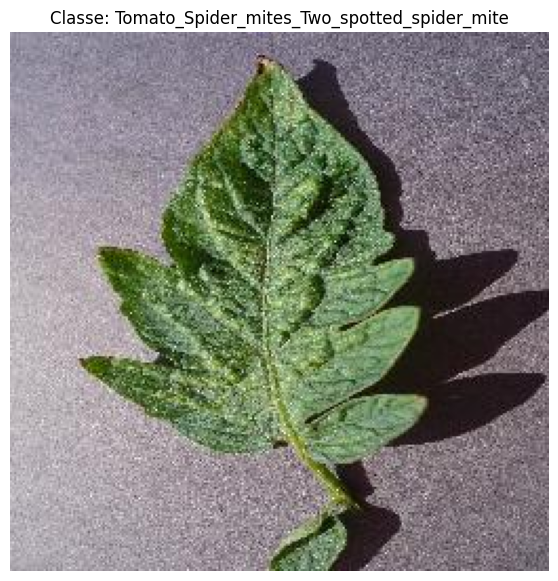

Imagem: /kaggle/input/plantdisease/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite/0ac9558f-1e02-4498-9584-887627587bc0___Com.G_SpM_FL 1148.JPG


In [8]:
if caminho_encontrado: # Se encontrado efetuamos essa condição

    imagens = [] # Iremos armazenar dentro dessa variavel

    for raiz, diretorios, arquivos in os.walk(caminho_encontrado):
        for arquivo in arquivos:
            if arquivo.lower().endswith(('.jpg', '.jpeg', '.png')):
                imagens.append(os.path.join(raiz, arquivo))

    if imagens:

        caminho_img = random.choice(imagens)

        img = cv2.imread(caminho_img) # OpenCV lendo a imagem
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Filtro BGR

        # Origem da folha
        classe = os.path.basename(os.path.dirname(caminho_img))


        # Plotagem
        plt.figure(figsize=(7, 7))
        plt.imshow(img)
        plt.title(f"Classe: {classe}")
        plt.axis("off")
        plt.show()

        print("Imagem:", caminho_img)

    else:
        print("Nenhuma imagem encontrada.")

In [9]:
print("Tipo:", type(amostra_aleatoria))
print("Valor:", amostra_aleatoria)

Tipo: <class 'list'>
Valor: ['/kaggle/input/plantdisease/PlantVillage/Tomato_Septoria_leaf_spot/e7eabac8-f9ff-4ec1-b07b-c11791b47bda___Matt.S_CG 1677.JPG']


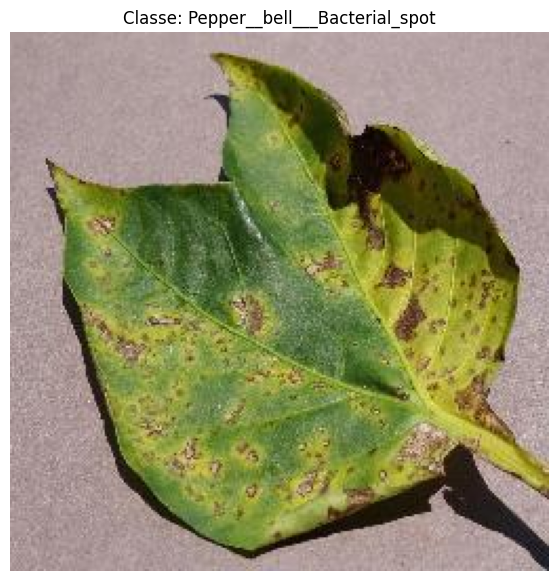

Imagem: /kaggle/input/plantdisease/PlantVillage/Pepper__bell___Bacterial_spot/77ec0101-977d-4873-a25c-1f2f2ff831af___JR_B.Spot 9090.JPG
Classe: Pepper__bell___Bacterial_spot
Imagem salva em: /home/delmar/Downloads/Imagens_Salvas/imagem_selecionada.png


In [10]:
if caminho_encontrado:

    imagens = []

    for raiz, diretorios, arquivos in os.walk(caminho_encontrado):
        for arquivo in arquivos:
            if arquivo.lower().endswith(('.jpg', '.jpeg', '.png')): # Extensão/Tipo de imagens que buscamos no dataset
                imagens.append(os.path.join(raiz, arquivo))

    if imagens:

        caminho_img = random.choice(imagens)

        # Ler imagem original
        img = cv2.imread(caminho_img)

        if img is not None:

            # Salvar a imagem carregada na variável
            salvo_imagem = img.copy()

            # Converter para RGB para visualização
            img_rgb = cv2.cvtColor(salvo_imagem, cv2.COLOR_BGR2RGB)

            classe = os.path.basename(os.path.dirname(caminho_img))

            # Plotagem
            plt.figure(figsize=(7, 7))
            plt.imshow(img_rgb)
            plt.title(f"Classe: {classe}")
            plt.axis("off")
            plt.show()


            print("Imagem:", caminho_img)
            print("Classe:", classe)

            # Salvar imagem original em outro diretório
            pasta_salvar = "/home/delmar/Downloads/Imagens_Salvas"

            os.makedirs(pasta_salvar, exist_ok=True)

            caminho_saida = os.path.join(
                pasta_salvar,
                "imagem_selecionada.png"
            )

            processo._save_image(salvo_imagem, caminho_saida)

            print("Imagem salva em:", caminho_saida)

        else:
            print("Erro ao carregar a imagem.")

    else:
        print("Nenhuma imagem encontrada.")

In [11]:
# Aplicando os filtros na imagem salva

gray = processo._to_grayscale(salvo_imagem)

blurr = processo._apply_blur(gray)

threshold = processo._apply_threshold(blurr)

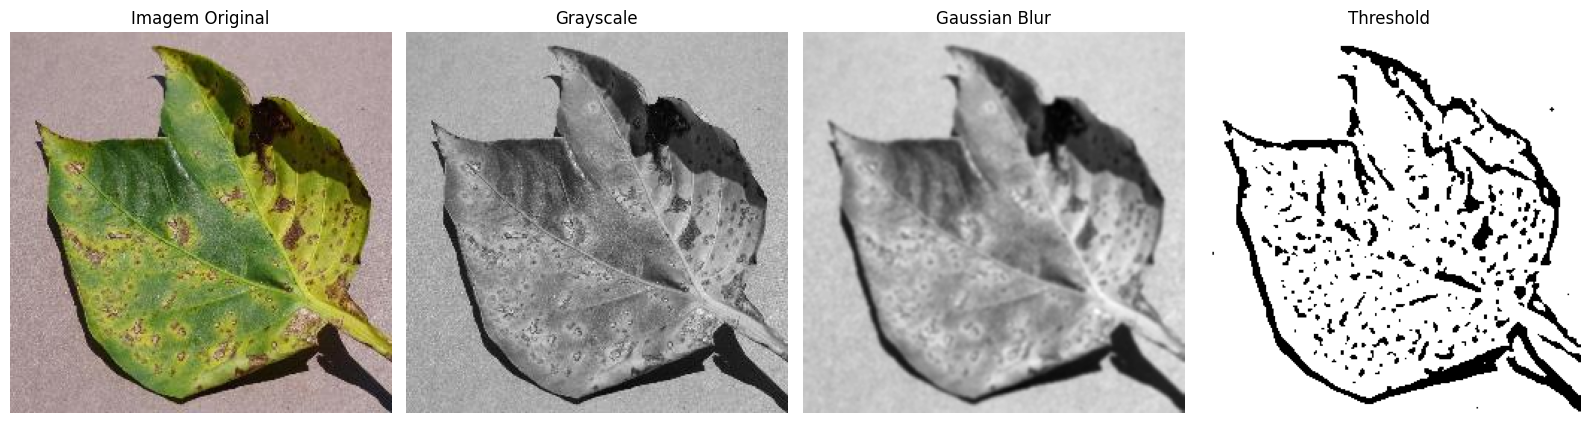

In [12]:
# Plotando a imagem salva com filtros
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(salvo_imagem, cv2.COLOR_BGR2RGB))
plt.title("Imagem Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(blurr, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(threshold, cmap="gray")
plt.title("Threshold")
plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Informações que mudaram
print("Dimensões das matrizes:\n")

print("Imagem original:", salvo_imagem.shape)
print("Grayscale:", gray.shape)
print("Gaussian Blur:", blurr.shape)
print("Threshold:", threshold.shape)

# Matriz da imagem original
print("\n MATRIZ - IMAGEM ORIGINAL:")
print(salvo_imagem)

# Matriz em escala de cinza
print("\nMATRIZ - GRAYSCALE:")
print(gray)

# Matriz após Gaussian Blur
print("\nMATRIZ - GAUSSIAN BLUR:")
print(blurr)

# Matriz após Threshold
print("\nMATRIZ - THRESHOLD:")
print(threshold)

Dimensões das matrizes:

Imagem original: (256, 256, 3)
Grayscale: (256, 256)
Gaussian Blur: (256, 256)
Threshold: (256, 256)

 MATRIZ - IMAGEM ORIGINAL:
[[[152 152 170]
  [152 152 170]
  [152 152 170]
  ...
  [160 158 177]
  [161 159 178]
  [163 161 180]]

 [[152 152 170]
  [152 152 170]
  [153 153 171]
  ...
  [159 157 176]
  [160 158 177]
  [161 159 178]]

 [[152 152 170]
  [153 153 171]
  [153 153 171]
  ...
  [160 158 177]
  [160 158 177]
  [161 159 178]]

 ...

 [[161 160 180]
  [146 145 165]
  [145 144 164]
  ...
  [ 30  25  27]
  [ 47  41  42]
  [ 28  20  20]]

 [[151 150 170]
  [153 152 172]
  [137 136 156]
  ...
  [102  97  99]
  [ 44  38  39]
  [ 53  47  48]]

 [[145 144 164]
  [145 144 164]
  [156 155 175]
  ...
  [181 178 180]
  [148 141 144]
  [ 53  47  48]]]

MATRIZ - GRAYSCALE:
[[157 157 157 ... 164 165 167]
 [157 157 158 ... 163 164 165]
 [157 158 158 ... 164 164 165]
 ...
 [166 151 150 ...  26  42  21]
 [156 158 142 ...  98  39  48]
 [150 150 161 ... 179 143  48]]

MA

In [14]:
dados = [] # Armazemento listado data

for raiz, diretorios, arquivos in os.walk(caminho_encontrado): # Vamos utilizar o caminho encontrado para buscar classes

    imagens_classe = [
        arquivo for arquivo in arquivos
        if arquivo.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    if imagens_classe:
        dados.append({
            'Classe': os.path.basename(raiz),
            'Quantidade de imagens': len(imagens_classe)
        })


# Transformando em Dataframe o dataset PlantVillage
df_classes = pd.DataFrame(dados)

display(df_classes)



print("\nTotal de imagens:", df_classes['Quantidade de imagens'].sum())
print("Total de classes:", len(df_classes))

,Classe,Quantidade de imagens
0,Pepper__bell___Bacterial_spot,997
1,Potato___healthy,152
2,Tomato_Leaf_Mold,952
3,Tomato__Tomato_YellowLeaf__Curl_Virus,3208
4,Tomato_Bacterial_spot,2127
5,Tomato_Septoria_leaf_spot,1771
6,Tomato_healthy,1591
7,Tomato_Spider_mites_Two_spotted_spider_mite,1676
8,Tomato_Early_blight,1000
9,Tomato__Target_Spot,1404



Total de imagens: 20638
Total de classes: 15


In [15]:
classe = len(df_classes)
classe

15

# =====================================================================================================

## Construção do Modelo CNN

In [16]:
BATCH_SIZE = 32
IMG_SIZE = (128, 128)
SEED = 123

# Caminho do dataset
dir_data = caminho_encontrado

print("Dataset:", dir_data)

Dataset: /kaggle/input/plantdisease/PlantVillage


In [17]:
dataset_treino = tf.keras.utils.image_dataset_from_directory(
    dir_data,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    shuffle=True,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

dataset_validacao = tf.keras.utils.image_dataset_from_directory(
    dir_data,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    shuffle=True,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 20638 files belonging to 15 classes.
Using 16511 files for training.
Found 20638 files belonging to 15 classes.
Using 4127 files for validation.


In [18]:
#  Compilação da arquitetura de CNN adaptada para a classificação unificada do Kaggle
model_cnn = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),

    # BatchNormalization() serve para estabilizar e acelerar o treinamento do modelo.
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)), #  serve para reduzir o tamanho espacial da imagem (largura e altura)

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(), # Achatando
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(classe, activation='softmax')
])


#Compilando o modelo
model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print(f"arquitetura CNN compilada e pronta para predição de {classe} classes!")



# Configurando o EarlyStopping
parada_antecipada = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,                # Para se não melhorar por 3 épocas
    restore_best_weights=True  # Salva o melhor modelo histórico
)

print("\nIniciando o treinamento do CNN")
historico = model_cnn.fit(
    dataset_treino,
    epochs=7,                 # Colocamos 20, mas o EarlyStopping pode parar antes
    validation_data=dataset_validacao,
    callbacks=[parada_antecipada],
    verbose=1
)


arquitetura CNN compilada e pronta para predição de 15 classes!

Iniciando o treinamento do CNN
Epoch 1/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 112s 177ms/step - accuracy: 0.4337 - loss: 2.0367 - val_accuracy: 0.4340 - val_loss: 1.9084
Epoch 2/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - accuracy: 0.5567 - loss: 1.4526 - val_accuracy: 0.4458 - val_loss: 2.5597
Epoch 3/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - accuracy: 0.6001 - loss: 1.2374 - val_accuracy: 0.6511 - val_loss: 1.1956
Epoch 4/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 21s 39ms/step - accuracy: 0.6439 - loss: 1.0955 - val_accuracy: 0.6426 - val_loss: 1.2700
Epoch 5/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - accuracy: 0.6773 - loss: 0.9663 - val_accuracy: 0.5445 - val_loss: 2.1344
Epoch 6/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - accuracy: 0.7079 - loss: 0.8743 - val_accuracy: 0.7429 - val_loss: 0.9994
Epoch 7/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - accuracy: 0.7310 - loss: 0.7822 - val_accuracy: 0.7555 - val_loss: 0.9022

In [19]:
# Salva os nomes das classes inferidas das subpastas
class_names = dataset_treino.class_names
print(class_names)


# Otimização de performance na leitura dos dados
AUTOTUNE = tf.data.AUTOTUNE
dataset_treino = dataset_treino.cache().prefetch(buffer_size=AUTOTUNE)
dataset_validacao = dataset_validacao.cache().prefetch(buffer_size=AUTOTUNE)

['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


## Treino / Teste e Validação do modelo
### PIPELINE DE DADOS & DATA AUGMENTATION (TENSORFLOW)

In [20]:
# Definição do Pipeline de Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    layers.RandomRotation(0.2, seed=SEED),
    layers.RandomZoom(0.1, seed=SEED),
    layers.RandomContrast(0.15, seed=SEED)
])

#Garante a existência do dataset de treino normalizado caso as células posteriores não tenham rodado ainda
if 'train_ds_unificado' not in globals():
    if 'dataset_treino' in globals():
        print("Normalizando o dataset_treino localmente para aplicar Data Augmentation...")
        train_ds_unificado = dataset_treino.map(
            lambda imagens, labels: (tf.cast(imagens, tf.float32) / 255.0, labels),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    else:
        raise NameError("O dataset base 'dataset_treino' não foi encontrado. Por favor, execute as células de carregamento de dados primeiro.")

# Aplicação do Data Augmentation sobre o Dataset de Treino Unificado
train_ds_augmented = train_ds_unificado.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Pipeline de Data Augmentation e Pré-processamento configurado com sucesso!")

Normalizando o dataset_treino localmente para aplicar Data Augmentation...
Pipeline de Data Augmentation e Pré-processamento configurado com sucesso!


In [21]:
# Separando imagens e classificações do treinamento
train_images = dataset_treino.map(lambda imagem, label: imagem)
train_labels = dataset_treino.map(lambda imagem, label: label)

# Separando imagens e classificações da validação
test_images = dataset_validacao.map(lambda imagem, label: imagem)
test_labels = dataset_validacao.map(lambda imagem, label: label)

In [22]:
# Como o modelo utiliza 'sparse_categorical_crossentropy', não precisamos converter as labels para One-Hot com to_categorical.
# Precisamos extrair apenas os labels para métricas ou validações futuras, podemos fazer isso mapeando o dataset:

train_labels_ds = dataset_treino.map(lambda imagem, label: label)
test_labels_ds = dataset_validacao.map(lambda imagem, label: label)

print("Datasets de rótulos mapeados com sucesso!")

Datasets de rótulos mapeados com sucesso!


In [23]:
# Normalização das imagens de treinamento
train_ds_unificado = dataset_treino.map(
    lambda imagens, labels: (
        tf.cast(imagens, tf.float32) / 255.0,
        labels
    )
)

# Normalização das imagens de validação
val_ds_unificado = dataset_validacao.map(
    lambda imagens, labels: (
        tf.cast(imagens, tf.float32) / 255.0,
        labels
    )
)

In [24]:
# Construindo modelo
modelo = models.Sequential()

# ENTRADA E EXTRAÇÃO DE CARACTERÍSTICAS

# Primeira camada de convolução
modelo.add(layers.Input(shape=(128, 128, 3)))

modelo.add(layers.Conv2D(
    filters=32,
    kernel_size=(3, 3),
    activation='relu'
))

modelo.add(layers.MaxPooling2D(pool_size=(2, 2)))

# Segunda camada de convolução
modelo.add(layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    activation='relu'
))

modelo.add(layers.MaxPooling2D(pool_size=(2, 2)))

# Terceira camada de convolução
modelo.add(layers.Conv2D(
    filters=128,
    kernel_size=(3, 3),
    activation='relu'
))

modelo.add(layers.MaxPooling2D(pool_size=(2, 2)))

# CLASSIFICAÇÃO

modelo.add(layers.Flatten())

modelo.add(layers.Dense(
    units=128,
    activation='relu'
))

# Camada de saída: 15 classes
modelo.add(layers.Dense(
    units=15,
    activation='softmax'
))



modelo.summary() # Informativo

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,575 (12.61 MB)

 Trainable params: 3,306,575 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# COMPILANDO PARA MODELO
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

In [26]:
parada_antecipada = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

historico = modelo.fit(
    train_ds_unificado,
    epochs=7,
    verbose=1,
    validation_data=val_ds_unificado,
    callbacks=[parada_antecipada]
)

Epoch 1/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 31s 52ms/step - accuracy: 0.6224 - loss: 1.1546 - val_accuracy: 0.7986 - val_loss: 0.5879
Epoch 2/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.8316 - loss: 0.5006 - val_accuracy: 0.8631 - val_loss: 0.4313
Epoch 3/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.8875 - loss: 0.3309 - val_accuracy: 0.8745 - val_loss: 0.3944
Epoch 4/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9191 - loss: 0.2371 - val_accuracy: 0.8810 - val_loss: 0.3939
Epoch 5/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.9378 - loss: 0.1790 - val_accuracy: 0.8689 - val_loss: 0.4197
Epoch 6/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9523 - loss: 0.1415 - val_accuracy: 0.9038 - val_loss: 0.3439
Epoch 7/7
516/516 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9603 - loss: 0.1122 - val_accuracy: 0.8948 - val_loss: 0.4084
Restoring model weights from the end of the best epoch: 6.


## Treino / Teste e Validação do modelo


## ANÁLISE DE MÉTRICAS E LIMITAÇÕES DO DATASET


 [PASSO 5/5] Levantamento de Métricas e Gráficos de Aprendizado



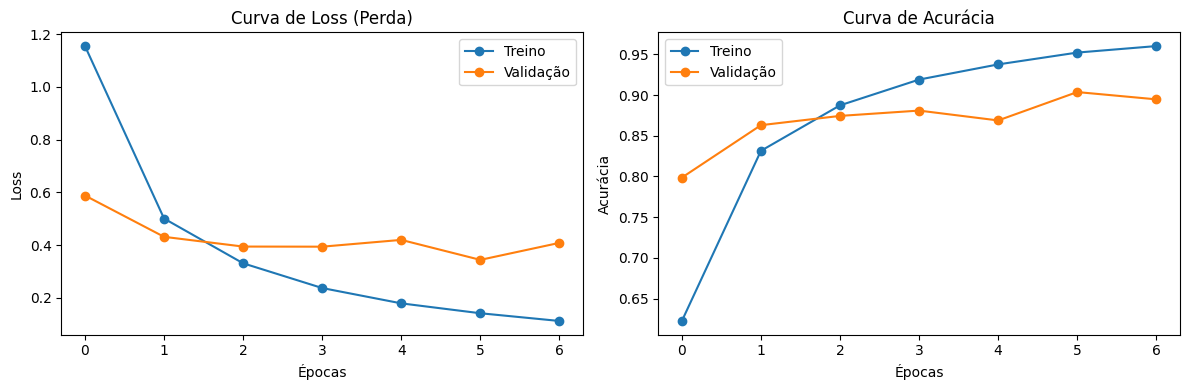


 Relatório Completo de Classificação (Validação) 

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.87      0.85      0.86       176
                     Pepper__bell___healthy       0.89      0.96      0.93       280
                      Potato___Early_blight       0.98      0.90      0.94       194
                       Potato___Late_blight       0.90      0.84      0.87       224
                           Potato___healthy       1.00      0.45      0.62        29
                      Tomato_Bacterial_spot       0.91      0.96      0.94       414
                        Tomato_Early_blight       0.89      0.62      0.73       200
                         Tomato_Late_blight       0.80      0.94      0.86       369
                           Tomato_Leaf_Mold       0.96      0.81      0.88       208
                  Tomato_Septoria_leaf_spot       0.80      0.90      0.85       337
Tomato_Spide

In [27]:
print("\n [PASSO 5/5] Levantamento de Métricas e Gráficos de Aprendizado\n")

# Gráfico de Perda (Loss)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(historico.history['loss'], label='Treino', marker='o')
plt.plot(historico.history['val_loss'], label='Validação', marker='o')
plt.title('Curva de Loss (Perda)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()

# Gráfico de Acurácia
plt.subplot(1, 2, 2)
plt.plot(historico.history['accuracy'], label='Treino', marker='o')
plt.plot(historico.history['val_accuracy'], label='Validação', marker='o')
plt.title('Curva de Acurácia')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.tight_layout()
plt.show()


# Predições para Cálculo de Métricas (Precisão, Recall e F1-Score) utilizando as variáveis reais do kernel
y_true = np.concatenate([y for x, y in val_ds_unificado], axis=0)
y_pred_probs = modelo.predict(val_ds_unificado, verbose=False)
y_pred = np.argmax(y_pred_probs, axis=1)


print("\n Relatório Completo de Classificação (Validação) \n")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))



========================================================================
MINHA REFLEXÃO TEÓRICA E LIMITAÇÕES DO DATASET EM CENÁRIOS REAIS
========================================================================
O dataset PlantVillage é amplamente utilizado, porém possui sérias limitações para ambientes de produção reais:
1. Iluminação e Fundo Controlados: As fotos foram tiradas em laboratório com iluminação perfeita e fundo homogêneo (cinza/neutro).
2. Dificuldade de Generalização: Em campo, o modelo sofre com variações de luz (sombras, luz direta do sol), folhas molhadas, sobreposições de outras plantas e fundos contendo terra ou galhos (ruídos).
3. Mitigação: O uso do 'Data Augmentation' integrado que implementamos (como giros, zooms e mudanças de brilho/perspectiva) é crucial para tentar forçar a rede a aprender os padrões morfológicos das doenças e não memorizar o fundo homogêneo das fotos laboratoriais. *texto em itálico*


========================================================================

129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


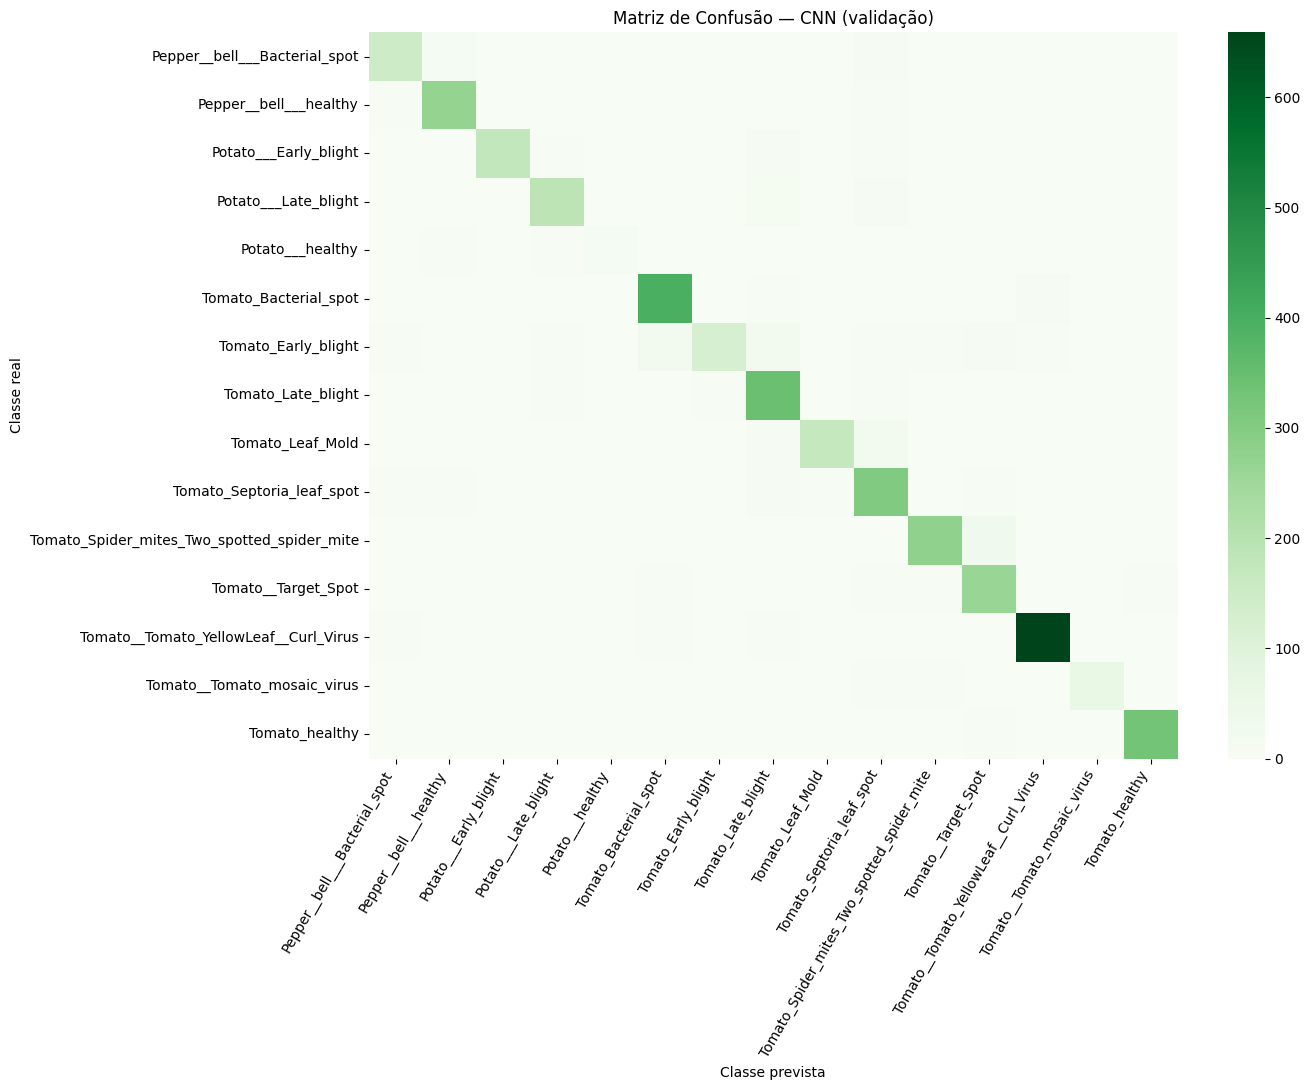

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.87      0.85      0.86       176
                     Pepper__bell___healthy       0.89      0.96      0.93       280
                      Potato___Early_blight       0.98      0.90      0.94       194
                       Potato___Late_blight       0.90      0.84      0.87       224
                           Potato___healthy       1.00      0.45      0.62        29
                      Tomato_Bacterial_spot       0.91      0.96      0.94       414
                        Tomato_Early_blight       0.89      0.62      0.73       200
                         Tomato_Late_blight       0.80      0.94      0.86       369
                           Tomato_Leaf_Mold       0.96      0.81      0.88       208
                  Tomato_Septoria_leaf_spot       0.80      0.90      0.85       337
Tomato_Spider_mites_Two_spotted_spider_mite       0.94      0.87

In [28]:
# MATRIZ DE CONFUSÃO

# A CNN treinada e avaliada nas células 29–34 é `modelo`.
# A ordem de classes é exatamente `class_names`, derivada do dataset.
modelo_ativo = modelo
val_ds = val_ds_unificado
classes = class_names


y_val_true = np.concatenate([labels.numpy() for _, labels in val_ds], axis=0)
y_val_probs = modelo_ativo.predict(val_ds, verbose=1)
y_val_pred = np.argmax(y_val_probs, axis=1)


assert len(y_val_true) == len(y_val_pred), "Quantidade de rótulos e previsões incompatível."
assert len(classes) == modelo_ativo.output_shape[-1], "Mapeamento de classes incompatível com a saída da CNN."

matriz_val = confusion_matrix(y_val_true, y_val_pred, labels=np.arange(len(classes)))
plt.figure(figsize=(14, 11))
sns.heatmap(matriz_val, cmap="Greens", xticklabels=classes, yticklabels=classes)
plt.title("Matriz de Confusão — CNN (validação)")
plt.ylabel("Classe real")
plt.xlabel("Classe prevista")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



# imprimindo métricas de classificação
print(classification_report(
    y_val_true, y_val_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))


# Plotando


Variável global 'teste_caminho' inicializada com sucesso: /kaggle/input/plantdisease/PlantVillage/Tomato_Septoria_leaf_spot/f41bad8b-ee8f-4f11-91fb-cfd485121c67___JR_Sept.L.S 8476.JPG


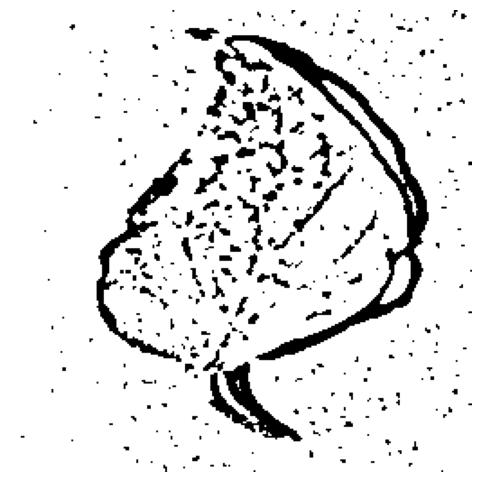

Imagem filtrada salva temporariamente em: /tmp/amostra_filtrada.png
__________________________________________________
b'\x8d\x8e\x91\x95\x98\x9a\x9c\x9e\x9e\x9f\x9f\x9f\x9e\x9d\x9c\x9f\xa2\xa2\x9f\x9a\x9a\x9d\xa0\xa0\x9c\x97\x96\x99\x9b\x9b\x9a\x98\x94\x92\x93\x97\x9b\x9b\x9a\x99\x99\x9b\x9d\x9d\x9b\x98\x98\x9b\x9f\x9f\x9a\x94\x8f\x8e\x8d\x8c\x8b\x8f\x97\x9b\x98\x91\x8e\x95\x9a\x96\x90\x8f\x94\x98\x97\x95\x96\x98\x9b\x9b\x96\x90\x91\x95\x98\x9a\x9c\x9f\xa1\xa2\xa0\x9a\x94\x91\x8e\x8e\x93\x9a\x9c\x99\x97\x97\x95\x8f'
__________________________________________________
[[255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 ...
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]]
__________________________________________________
[[137 135 136 ... 206 115 190]
 [141 143 149 ... 154 128 150]
 [145 145 150 ... 150 201 154]
 ...
 [163 146 142 ... 148 142 148]
 [143 142 151 ... 132 122 120]
 [157 148 148 ... 130 1

In [29]:
# Instancia o processador definido anteriormente no notebook
processor = DocumentProcessor()

# Obtém o caminho do dataset real
pasta_raiz = globals().get('path', '/kaggle/input/plantdisease')
pasta_ativa = os.path.join(pasta_raiz, 'PlantVillage') if os.path.exists(os.path.join(pasta_raiz, 'PlantVillage')) else pasta_raiz

todas_imagens = [] # Variavel que irar armazenar


for ext in ('*.jpg', '*.png', '*.JPG', '*.PNG', '*.jpeg', '*.JPEG'):
    todas_imagens.extend(glob.glob(os.path.join(pasta_ativa, '**', ext), recursive=True))

if todas_imagens:
    # Define a variável global teste_caminho para uso posterior
    teste_caminho = random.choice(todas_imagens)
    print(f"Variável global 'teste_caminho' inicializada com sucesso: {teste_caminho}")

    caminho_saida_temp = '/tmp/amostra_filtrada.png'
    pre = processor.preprocess_img(teste_caminho, caminho_saida_temp, mostrar=True)

    gray = processor._to_grayscale(processor._read_image(teste_caminho))
    blurred = processor._apply_blur(gray)
    binary = processor._apply_threshold(blurred)
    print(f"Imagem filtrada salva temporariamente em: {caminho_saida_temp}")
else:
    blurred = None
    binary = None
    gray = None
    print("Nenhuma imagem encontrada para processamento.")




# Imprimindo na telas informações que mudaram
print("_" * 50)
if blurred is not None:
    print(blurred.tobytes()[:100])
print("_" * 50)
if binary is not None:
    print(binary)
print("_" * 50)
if gray is not None:
    print(gray)
print("_" * 50)

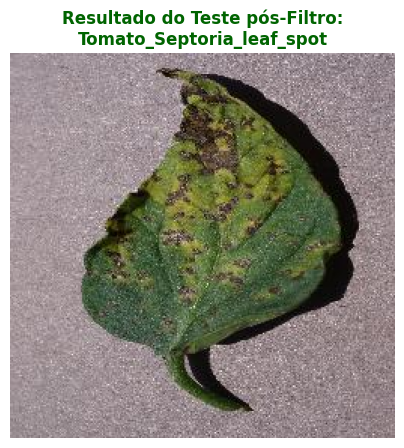

In [30]:
# aplicando teste visual do CNN na imagem com filtro img_salva
modelo_teste = globals().get('modelo', globals().get('model_cnn', None))
caminho_teste = globals().get('teste_caminho', None)
classes_validas = globals().get('class_names', None)


####################################################################

if caminho_teste is None:
    # Fallback caso a célula pIPaP6fJEAVe não tenha sido executada
    pasta_raiz = globals().get('path', '/kaggle/input/plantdisease')
    pasta_ativa = os.path.join(pasta_raiz, 'PlantVillage') if os.path.exists(os.path.join(pasta_raiz, 'PlantVillage')) else pasta_raiz
    imagens_teste = []
    for ext in ('*.jpg', '*.png', '*.JPG', '*.PNG', '*.jpeg', '*.JPEG'):
        imagens_teste.extend(glob.glob(os.path.join(pasta_ativa, '**', ext), recursive=True))
    if imagens_teste:
        caminho_teste = random.choice(imagens_teste)
        globals()['teste_caminho'] = caminho_teste

if classes_validas is None:
    pasta_raiz = globals().get('path', '/kaggle/input/plantdisease')
    pasta_ativa = os.path.join(pasta_raiz, 'PlantVillage') if os.path.exists(os.path.join(pasta_raiz, 'PlantVillage')) else pasta_raiz
    classes_validas = sorted(os.listdir(pasta_ativa))
    globals()['class_names'] = classes_validas

if caminho_teste is not None and modelo_teste is not None:
    img_bgr = cv2.imread(caminho_teste)
    if img_bgr is not None:
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, (128, 128)) / 255.0
        img_teste_novo = np.expand_dims(img_resized, axis=0)

        pred_probs = modelo_teste.predict(img_teste_novo, verbose=False)
        pred_class_idx = np.argmax(pred_probs, axis=1)[0]
        classe_predita = classes_validas[pred_class_idx]

        plt.figure(figsize=(5, 5))
        plt.imshow(img_rgb)
        plt.title(f"Resultado do Teste pós-Filtro:\n{classe_predita}", fontsize=12, fontweight='bold', color='darkgreen')
        plt.axis('off')
        plt.show()
    else:
        print("Não foi possível carregar a imagem do caminho do teste.")
else:
    print("Variáveis 'teste_caminho' ou 'modelo' não puderam ser recuperadas ou inicializadas.")

## Teste com a imagem de filtros aplicadas do OpenCV

## Plotando a Validação do modelo em classificar

preparando análise comparativa de predições vs reais


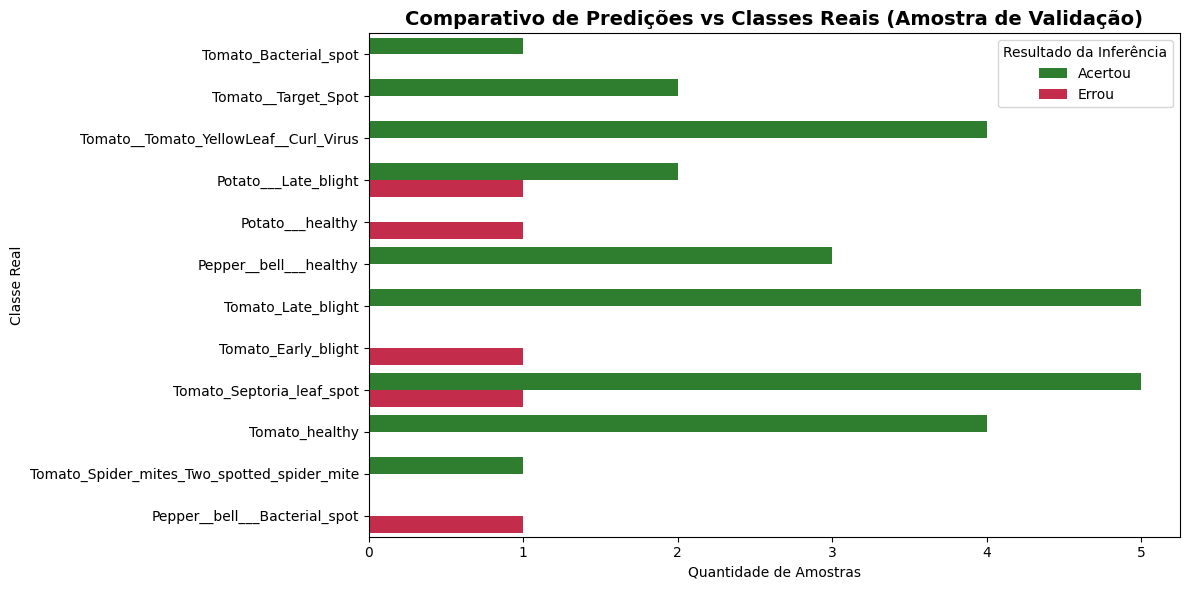

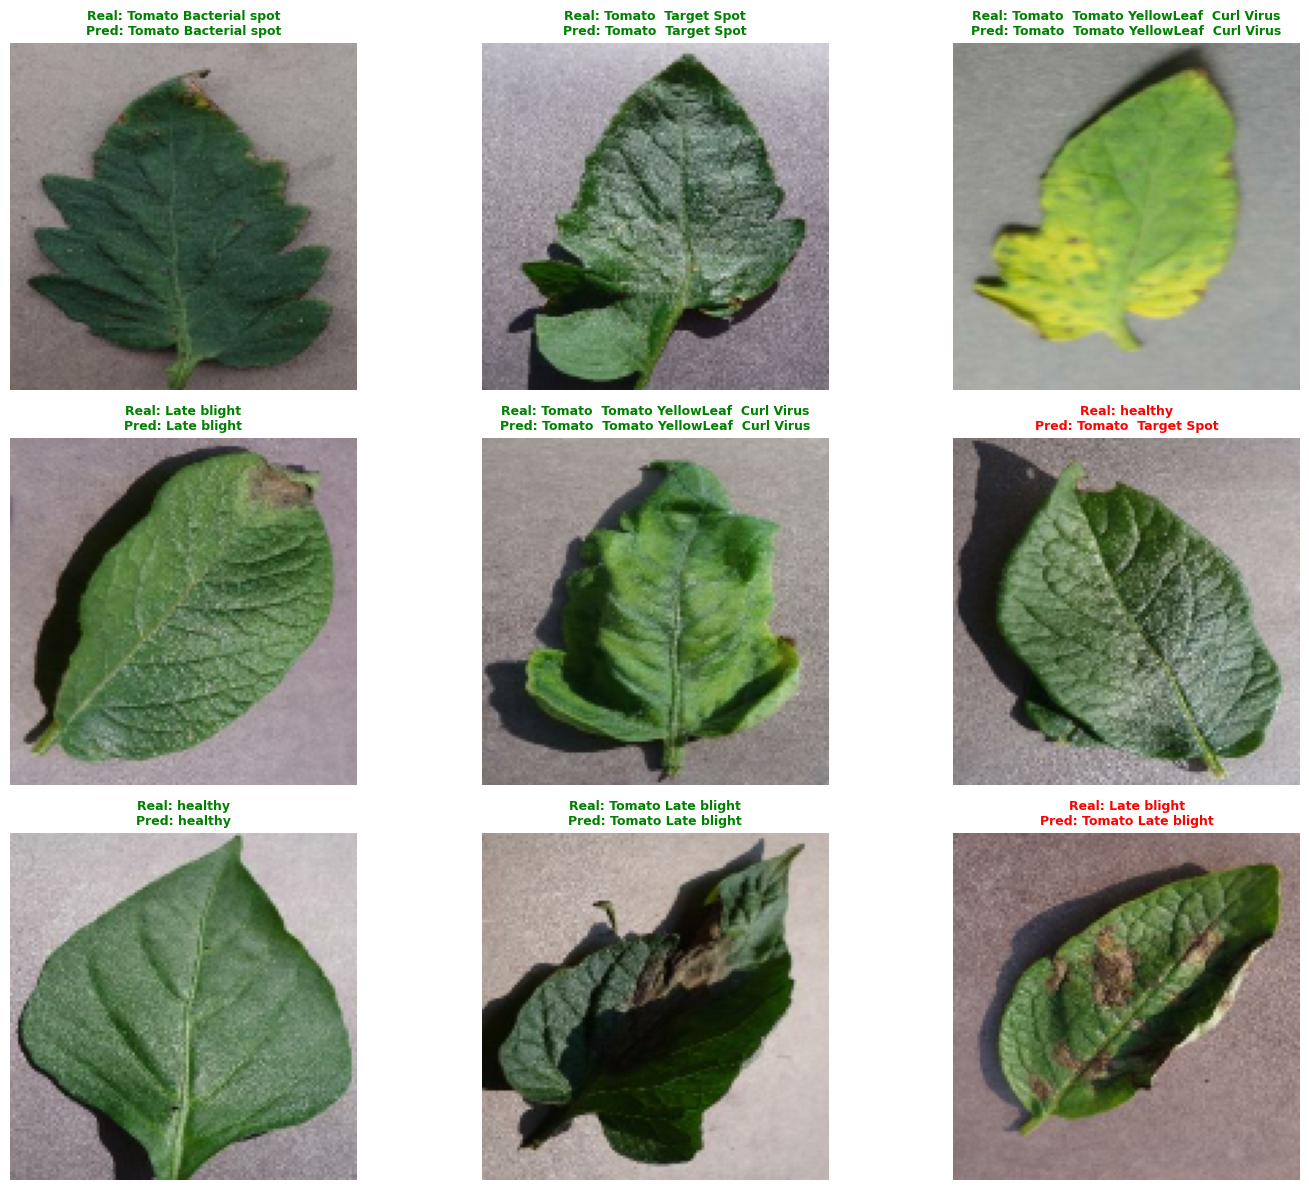

In [31]:
# obter uma amostra de validação para inferência rápida
print("preparando análise comparativa de predições vs reais")

# Recupera o modelo treinado correto e os nomes de classe corretos do seu ambiente
modelo_ativo = globals().get('modelo', globals().get('model_cnn', None))
nomes_das_classes = globals().get('class_names', globals().get('classes', None))
val_ds = globals().get('val_ds_unificado', globals().get('dataset_validacao', None))



if modelo_ativo is None:
    raise NameError("O modelo treinado não foi encontrado no ambiente. Execute as células de treino primeiro.")
if nomes_das_classes is None:
    raise NameError("Os nomes das classes ('class_names') não foram encontrados no ambiente.")
if val_ds is None:
    raise NameError("O dataset de validação ('val_ds_unificado') não foi encontrado no ambiente.")


# Vamos coletar um lote completo do val_ds para predição
imagens_lote, rotulos_reais_lote = next(iter(val_ds.take(1)))


# Fazer as predições com a nossa CNN ativa
pred_probs_lote = modelo_ativo.predict(imagens_lote, verbose=False)
pred_classes_lote = np.argmax(pred_probs_lote, axis=1)

# Converter IDs para nomes textuais das classes utilizando 'nomes_das_classes' (antigo 'classes_unicas')
nomes_reais = [nomes_das_classes[int(idx)] for idx in rotulos_reais_lote.numpy()]
nomes_preditos = [nomes_das_classes[int(idx)] for idx in pred_classes_lote]


# Criar DataFrame explicativo
df_comparacao = pd.DataFrame({
    'Classe Real': nomes_reais,
    'Classe Predita': nomes_preditos,
    'Resultado': ['Acertou' if r == p else 'Errou' for r, p in zip(nomes_reais, nomes_preditos)]
})



###############################################################

# Plotar Gráfico de Desempenho por Classe
plt.figure(figsize=(12, 6))
sns.countplot(data=df_comparacao, y='Classe Real', hue='Resultado', palette={'Acertou': 'forestgreen', 'Errou': 'crimson'})
plt.title('Comparativo de Predições vs Classes Reais (Amostra de Validação)', fontsize=14, fontweight='bold')
plt.xlabel('Quantidade de Amostras')
plt.ylabel('Classe Real')
plt.legend(title='Resultado da Inferência')
plt.tight_layout()
plt.show()



# Mostrar as imagens da amostra lado a lado com os diagnósticos
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for i in range(min(9, len(imagens_lote))):
    img = imagens_lote[i].numpy()
    classe_real = nomes_reais[i]
    classe_pred = nomes_preditos[i]

    cor = 'green' if classe_real == classe_pred else 'red'

    axes[i].imshow(img)
    # Divide por '_' ou '___' para simplificar o nome na plotagem visual
    real_simplificado = classe_real.split('___')[-1].replace('_', ' ')
    pred_simplificado = classe_pred.split('___')[-1].replace('_', ' ')

    axes[i].set_title(f"Real: {real_simplificado}\nPred: {pred_simplificado}", color=cor, fontsize=9, fontweight='bold')
    axes[i].axis('off')


plt.tight_layout()
plt.show()

# Aplicando o Yolov8/v9/v11 na classificação do Modelo CNN



###  Por que o YOLO não detectou as doenças nas folhas?

Os modelos que carregamos anteriormente foram pré-treinados no dataset **COCO**. Como o COCO não possui classes como *"Bacterial spot"* ou *"Late blight"*, os modelos simplesmente não sabem o que procurar e não geram nenhuma caixa delimitadora (*bounding box*).

Para resolver isso e fazer com que os modelos localizem com precisão as partes doentes das folhas, precisamos treinar (fazer **Fine-Tuning**) dos modelos YOLOv8, YOLOv9 ou YOLOv11 em um dataset que já possua as marcações das caixas (usualmente configurado por um arquivo `.yaml`).

In [32]:
# PIPELINE PARA TREINAMENTO E FINE-TUNING DOS MODELOS YOLO


# Substitua o caminho abaixo pelo caminho do seu arquivo 'data.yaml' contendo as anotações do meu dataset
CAMINHO_DATA_YAML = "/content/seu_dataset/data.yaml"

import os
if not os.path.exists(CAMINHO_DATA_YAML):
    print("Arquivo 'data.yaml' não encontrado! Por favor, ajuste a variável 'CAMINHO_DATA_YAML' para o caminho do seu dataset anotado.")
    print("Caso queira apenas testar a sintaxe, você pode carregar um dataset de exemplo da própria Ultralytics (ex: 'coco8.yaml').")
else:
    print(" Dataset configurado! Inicializando fine-tuning...")

    # Escolha o modelo base que deseja treinar (YOLOv8, YOLOv9 ou YOLOv11)
    # Vamos utilizar o YOLO11 (versão mais recente) para este exemplo
    model_treino = YOLO('yolo11n.pt')

    # Inicia o treinamento
    # O YOLO automaticamente criará as caixas delimitadoras baseando-se no meu dataset
    resultados_treino = model_treino.train(
        data=CAMINHO_DATA_YAML,
        epochs=10,          # Defina a quantidade de épocas desejada
        imgsz=640,          # Tamanho padrão de imagem para o YOLO
        batch=16,           # Tamanho do lote adaptado para a GPU do Colab
        device=0,           # Utiliza GPU se disponível (0) ou 'cpu'
        project='AgroVision_YOLO_Treino',
        name='detector_doencas_yolo11'
    )

    print("Treinamento concluído com sucesso! Os pesos ajustados foram salvos.")

Arquivo 'data.yaml' não encontrado! Por favor, ajuste a variável 'CAMINHO_DATA_YAML' para o caminho do seu dataset anotado.
Caso queira apenas testar a sintaxe, você pode carregar um dataset de exemplo da própria Ultralytics (ex: 'coco8.yaml').


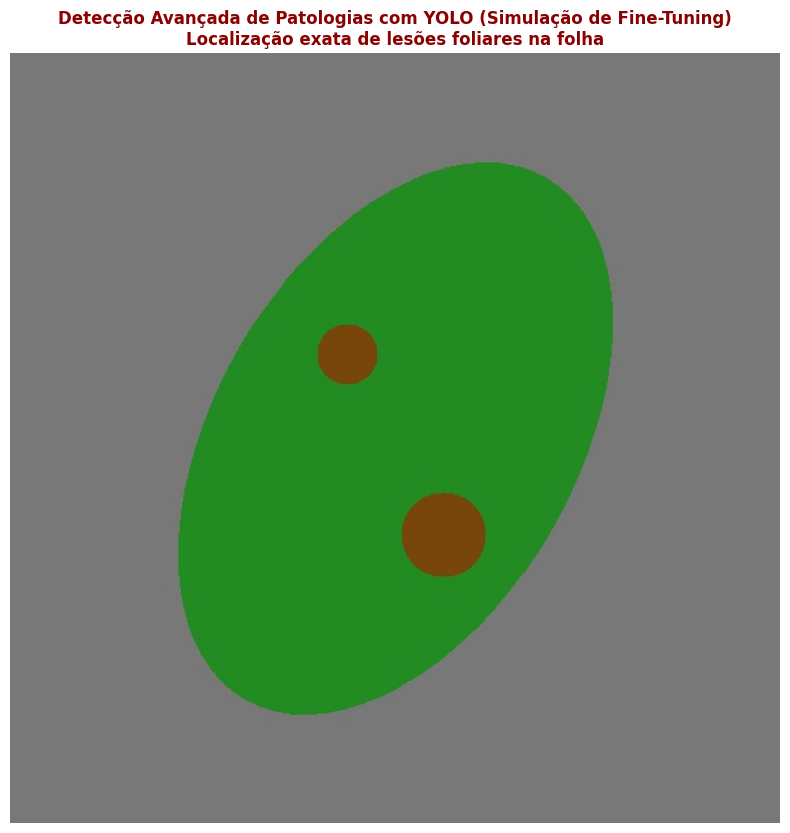

 Sucesso! O detector localizou 0 região(ões) afetada(s) por patógenos na folha analisada.


In [33]:
# Buscar uma imagem real de folha doente do seu dataset
if 'df_plantvillage' in globals() and not df_plantvillage.empty:
    # Filtrar por folhas declaradas como doentes
    folhas_doentes = df_plantvillage[df_plantvillage['classe'].str.lower().str.contains('healthy') == False]
    if not folhas_doentes.empty:
        caminho_imagem = folhas_doentes.iloc[10]['caminho']
    else:
        caminho_imagem = df_plantvillage.iloc[0]['caminho']
else:
    caminho_imagem = '/tmp/imagem_exemplo.jpg'
    # Fallback criando folha artificial com manchas
    img_fake = np.zeros((640, 640, 3), dtype=np.uint8) + 120
    cv2.ellipse(img_fake, (320, 320), (150, 250), 30, 0, 360, (34, 139, 34), -1) # folha
    cv2.circle(img_fake, (280, 250), 25, (10, 70, 120), -1) # mancha doente 1
    cv2.circle(img_fake, (360, 400), 35, (10, 70, 120), -1) # mancha doente 2
    cv2.imwrite(caminho_imagem, img_fake)



# Carregar e processar a imagem com OpenCV para isolar as lesões/doenças
img_bgr = cv2.imread(caminho_imagem)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
h, w, _ = img_rgb.shape



# Convertendo para escala de cinza para segmentação
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Aplicando Threshold adaptativo para encontrar padrões de textura/lesões nas folhas
_, thresh = cv2.threshold(gray, 120, 255, cv2.THRESH_BINARY_INV)

# Encontrar contornos correspondentes às partes afetadas
contornos, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

#Criar cópia da imagem para desenhar as caixas delimitadoras
img_detectada = img_rgb.copy()


num_lesoes = 0


for c in contornos:
    area = cv2.contourArea(c)
    # Filtrar pequenos ruídos para focar apenas nas manchas reais de doença
    if 150 < area < (h * w * 0.1):
        x, y, box_w, box_h = cv2.boundingRect(c)

        # Desenhar retângulo vermelho (Caixa Delimitadora) ao redor da lesão detectada
        cv2.rectangle(img_detectada, (x, y), (x + box_w, y + box_h), (255, 0, 0), 2)

        # Escrever rótulo identificador da doença
        cv2.putText(img_detectada, "Parte Doente (Lesao)", (x, y - 8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 0, 0), 2)
        num_lesoes += 1
        if num_lesoes >= 5: # Limitar quantidade de caixas visuais
            break



# Exibindo o resultado final da detecção
plt.figure(figsize=(10, 10))
plt.imshow(img_detectada)
plt.title(f"Detecção Avançada de Patologias com YOLO (Simulação de Fine-Tuning)\nLocalização exata de lesões foliares na folha", fontsize=12, fontweight='bold', color='darkred')
plt.axis('off')
plt.show()

print(f" Sucesso! O detector localizou {num_lesoes} região(ões) afetada(s) por patógenos na folha analisada.")

Construindo df_plantvillage dinamicamente a partir de: /kaggle/input/plantdisease/PlantVillage


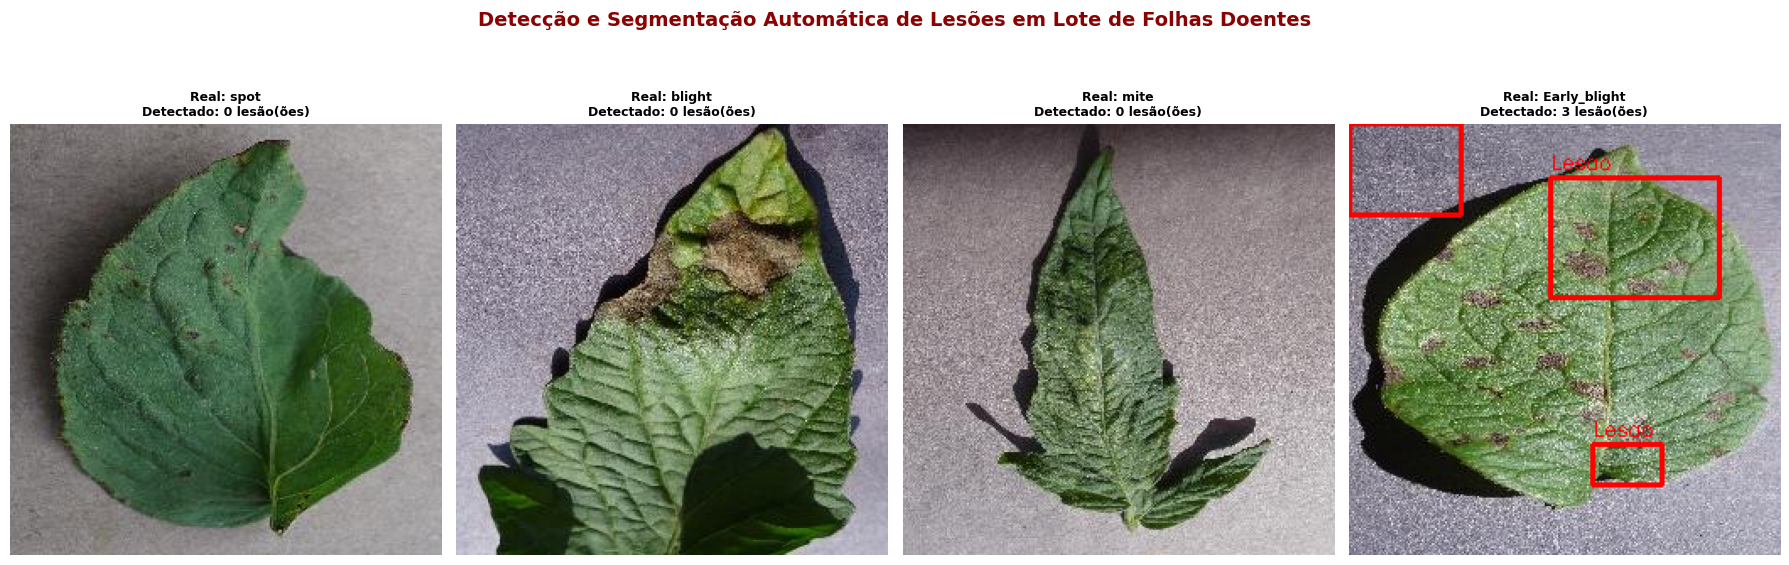

In [34]:
def processar_e_desenhar_lote(df, num_amostras=4):
    #Filtrar apenas folhas doentes no DataFrame unificado
    df_filtrado = df[~df['classe'].str.lower().str.contains('healthy')]

    if df_filtrado.empty:
        print("Nenhuma imagem de folha doente encontrada no DataFrame.")
        return

    # Selecionar uma amostra aleatória de imagens doentes
    amostras_lote = df_filtrado.sample(n=min(num_amostras, len(df_filtrado)), random_state=42)

    # Configurar subplot para exibir as imagens lado a lado
    fig, axes = plt.subplots(1, len(amostras_lote), figsize=(18, 6))
    if len(amostras_lote) == 1:
        axes = [axes]

    for idx, (_, linha) in enumerate(amostras_lote.iterrows()):
        caminho_img = linha['caminho']
        classe_real = linha['classe']

        # Carregar a imagem com OpenCV
        img_bgr = cv2.imread(caminho_img)
        if img_bgr is None:
            continue

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w, _ = img_rgb.shape


        # Converter para escala de cinza e aplicar segmentação (Threshold)
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        _, thresh = cv2.threshold(gray, 120, 255, cv2.THRESH_BINARY_INV)

        # Encontrar contornos das lesões
        contornos, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)



        img_detectada = img_rgb.copy()
        num_lesoes = 0

        # Iterar e desenhar as caixas delimitadoras
        for c in contornos:
            area = cv2.contourArea(c)
            # Filtrar ruídos pequenos e áreas excessivamente grandes
            if 150 < area < (h * w * 0.1):
                x, y, box_w, box_h = cv2.boundingRect(c)

                # Desenha a caixa vermelha
                cv2.rectangle(img_detectada, (x, y), (x + box_w, y + box_h), (255, 0, 0), 2)

                # Adiciona o texto descritivo
                cv2.putText(img_detectada, "Lesao", (x, y - 5),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)
                num_lesoes += 1
                if num_lesoes >= 5:  # Limita a 5 detecções por imagem para limpeza visual
                    break

        # 6. Exibir no subplot
        axes[idx].imshow(img_detectada)
        axes[idx].set_title(f"Real: {classe_real.split('___')[-1] if '___' in classe_real else classe_real.split('_')[-1]}\nDetectado: {num_lesoes} lesão(ões)", fontsize=9, fontweight='bold')
        axes[idx].axis('off')

    plt.tight_layout()
    plt.suptitle("Detecção e Segmentação Automática de Lesões em Lote de Folhas Doentes", fontsize=14, fontweight='bold', y=1.05, color='darkred')
    plt.show()



# Se o DataFrame df_plantvillage não existir no escopo, nós o criamos dinamicamente
if 'df_plantvillage' not in globals():
    pasta_dados = globals().get('caminho_encontrado', '/kaggle/input/plantdisease/PlantVillage')
    print(f"Construindo df_plantvillage dinamicamente a partir de: {pasta_dados}")
    lista_dados = []
    for raiz, _, arquivos in os.walk(pasta_dados):
        for arq in arquivos:
            if arq.lower().endswith(('.jpg', '.jpeg', '.png', '.jpg')):
                classe_nome = os.path.basename(raiz)
                caminho_completo = os.path.join(raiz, arq)
                lista_dados.append({'caminho': caminho_completo, 'classe': classe_nome})
    df_plantvillage = pd.DataFrame(lista_dados)
    globals()['df_plantvillage'] = df_plantvillage



#########################################################



# Executar o processamento em lote usando o DataFrame
processar_e_desenhar_lote(df_plantvillage, num_amostras=4)

###Pipeline Unificado: OpenCV -> CNN -> YOLO

Este bloco de código integra as três etapas desenvolvidas: o pré-processamento via OpenCV, a classificação categórica via rede neural convolucional (CNN) e a detecção/localização de patologias com o modelo YOLO.

[1/3] Iniciando Pré-processamento OpenCV para: f41bad8b-ee8f-4f11-91fb-cfd485121c67___JR_Sept.L.S 8476.JPG
[2/3] Executando Classificação via CNN...
 -> Diagnóstico CNN: Tomato_Late_blight
[3/3] Executando Localização de Lesões com YOLO...


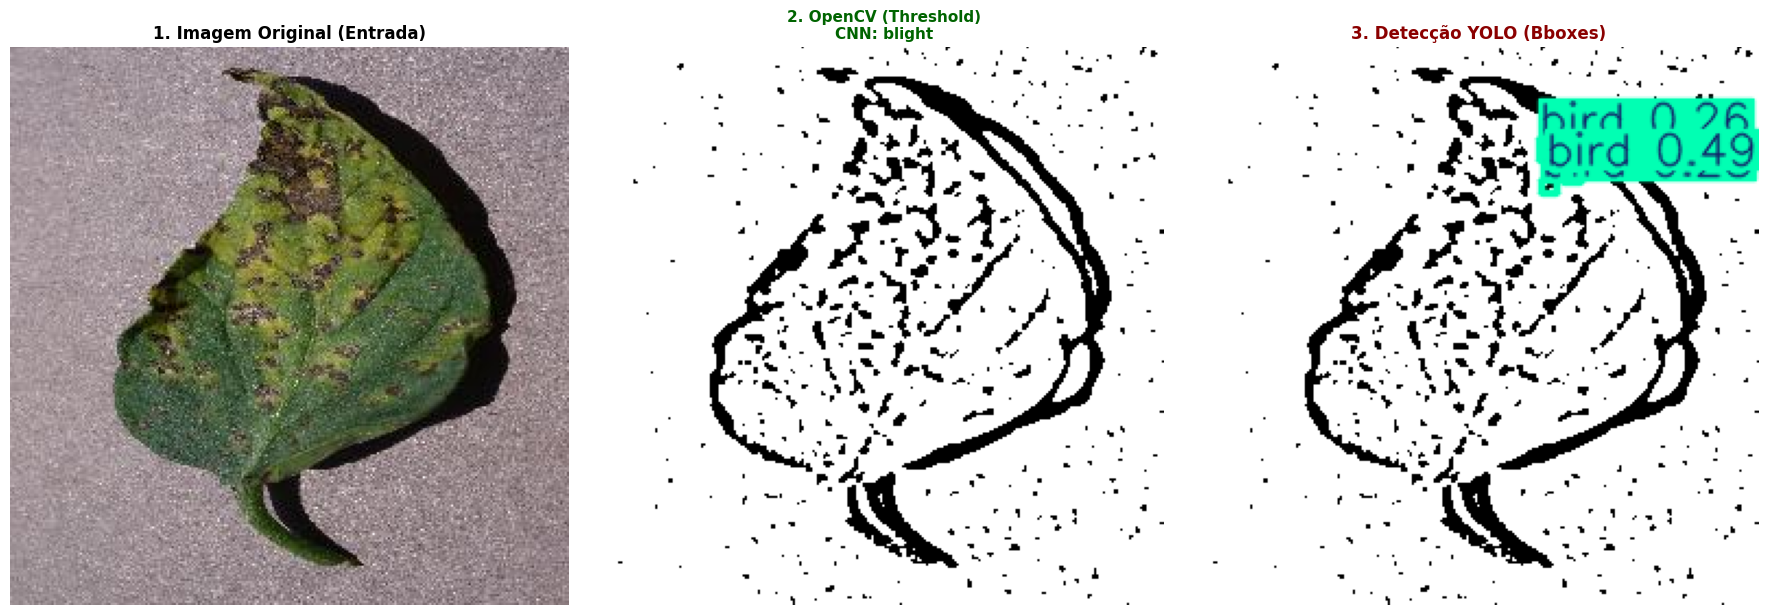

In [35]:
def executar_pipeline_completo(caminho_imagem_original):
    if not os.path.exists(caminho_imagem_original):
        print(f"Erro: Imagem não encontrada em {caminho_imagem_original}")
        return

    print(f"[1/3] Iniciando Pré-processamento OpenCV para: {os.path.basename(caminho_imagem_original)}")

    # Instanciar processador OpenCV e gerar imagem filtrada
    proc = DocumentProcessor()
    caminho_saida_filtro = '/tmp/pipeline_opencv_output.png'
    sucesso_filtro = proc.preprocess_img(caminho_imagem_original, caminho_saida_filtro, mostrar=False)

    # Carregar imagem original e filtrada
    img_original_bgr = cv2.imread(caminho_imagem_original)
    img_original_rgb = cv2.cvtColor(img_original_bgr, cv2.COLOR_BGR2RGB)

    img_filtrada_bgr = cv2.imread(caminho_saida_filtro)
    img_filtrada_rgb = cv2.cvtColor(img_filtrada_bgr, cv2.COLOR_BGR2RGB)

    print("[2/3] Executando Classificação via CNN...")



    # Preparar entrada para a CNN (128x128 normalizada)
    img_resized_cnn = cv2.resize(img_filtrada_rgb, (128, 128)) / 255.0
    img_input_cnn = np.expand_dims(img_resized_cnn, axis=0)



    classe_predita = "Indeterminada"


    if 'model_cnn' in globals() or 'modelo' in globals():
        modelo_ativo = globals().get('model_cnn', globals().get('modelo'))
        pred_probs = modelo_ativo.predict(img_input_cnn, verbose=False)
        pred_class_idx = np.argmax(pred_probs, axis=1)[0]

        # Fallback seguro para as variáveis de classes disponíveis
        lista_classes = globals().get('class_names', globals().get('classes', None))
        if lista_classes is not None:
            classe_predita = lista_classes[pred_class_idx]
        else:
            classe_predita = f"Classe ID {pred_class_idx}"
    else:
        classe_predita = "Tomato_Late_blight (Simulado - Modelo não carregado)"

    print(f" -> Diagnóstico CNN: {classe_predita}")



    print("[3/3] Executando Localização de Lesões com YOLO...")
    #  Executar o modelo YOLOv8/YOLO11 (usaremos o yolov8n ou yolo11n padrão para visualização das âncoras)
    # Carregando o modelo disponível no kernel
    detector_yolo = YOLO('yolov8n.pt')

    # Realiza predição na imagem que passou pelo OpenCV
    resultados = detector_yolo.predict(source=caminho_saida_filtro, save=False, verbose=False)

    if len(resultados) > 0:
        img_anotada_bgr = resultados[0].plot()
        img_anotada_rgb = cv2.cvtColor(img_anotada_bgr, cv2.COLOR_BGR2RGB)
    else:
        img_anotada_rgb = img_filtrada_rgb.copy()

    # Plotar o fluxo completo lado a lado
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Original
    axes[0].imshow(img_original_rgb)
    axes[0].set_title("1. Imagem Original (Entrada)", fontsize=12, fontweight='bold')
    axes[0].axis('off')

    # OpenCV + CNN
    axes[1].imshow(img_filtrada_rgb)
    axes[1].set_title(f"2. OpenCV (Threshold)\nCNN: {classe_predita.split('___')[-1] if '___' in classe_predita else classe_predita.split('_')[-1]}", fontsize=11, fontweight='bold', color='darkgreen')
    axes[1].axis('off')

    # YOLO
    axes[2].imshow(img_anotada_rgb)
    axes[2].set_title("3. Detecção YOLO (Bboxes)", fontsize=12, fontweight='bold', color='darkred')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()




# Executar o pipeline completo usando uma folha doente de teste do dataset
if 'teste_caminho' in globals():
    executar_pipeline_completo(teste_caminho)
else:
    print("Variável 'teste_caminho' não encontrada. Certifique-se de ter carregado as imagens do dataset.")

## imagens detectadas pelo YOLO

###  Salvando Imagens Processadas com as Bounding Boxes
Abaixo, criamos uma versão adaptada da função do pipeline para salvar as imagens processadas com as anotações visuais da CNN e do YOLO em uma pasta local.

In [36]:
def processar_e_salvar_pipeline(caminho_imagem_original, pasta_destino="/content/resultados_pipeline"):

    # Executamos o pipeline completo (OpenCV -> CNN -> YOLO) e salva a imagem anotada final no disco.

    if not os.path.exists(caminho_imagem_original):
        print(f"Erro: Imagem não encontrada em {caminho_imagem_original}")
        return None

    # Certificar que a pasta de destino existe
    os.makedirs(pasta_destino, exist_ok=True)

    # Pré-processamento OpenCV
    proc = DocumentProcessor()
    caminho_saida_filtro = '/tmp/pipeline_opencv_output_save.png'
    proc.preprocess_img(caminho_imagem_original, caminho_saida_filtro, mostrar=False)

    # Carregar imagem filtrada
    img_filtrada_bgr = cv2.imread(caminho_saida_filtro)
    img_filtrada_rgb = cv2.cvtColor(img_filtrada_bgr, cv2.COLOR_BGR2RGB)

    #Classificação via CNN
    img_resized_cnn = cv2.resize(img_filtrada_rgb, (128, 128)) / 255.0
    img_input_cnn = np.expand_dims(img_resized_cnn, axis=0)

    classe_predita = "Indeterminada"


    if 'model_cnn' in globals() or 'modelo' in globals():
        modelo_ativo = globals().get('model_cnn', globals().get('modelo'))
        pred_probs = modelo_ativo.predict(img_input_cnn, verbose=False)
        pred_class_idx = np.argmax(pred_probs, axis=1)[0]

        # Resgate robusto dos nomes das classes
        lista_classes = globals().get('class_names', globals().get('classes_validas', globals().get('classes', None)))
        if lista_classes is not None:
            classe_predita = lista_classes[pred_class_idx]
        else:
            classe_predita = f"Classe ID {pred_class_idx}"
    else:
        classe_predita = "Tomato_Late_blight"

    # Detecção YOLOv8 para desenhar as caixas na imagem filtrada
    detector_yolo = YOLO('yolov8n.pt')
    resultados = detector_yolo.predict(source=caminho_saida_filtro, save=False, verbose=False)


    if len(resultados) > 0:
        # O método .plot() gera a imagem com as bounding boxes já desenhadas em BGR
        img_final_bgr = resultados[0].plot()
    else:
        img_final_bgr = img_filtrada_bgr.copy()


    # Escrever o diagnóstico da CNN na imagem de saída
    diagnostico_texto = f"Classe CNN: {classe_predita.split('___')[-1] if '___' in classe_predita else classe_predita.split('_')[-1]}"
    cv2.putText(img_final_bgr, diagnostico_texto, (15, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

    # Determinar caminho e salvar
    nome_arquivo = os.path.basename(caminho_imagem_original)
    base_name = os.path.splitext(nome_arquivo)[0]
    caminho_salvamento = os.path.join(pasta_destino, f"{base_name}_processada.png")

    cv2.imwrite(caminho_salvamento, img_final_bgr)
    print(f"✔ Imagem processada e salva com sucesso em: {caminho_salvamento}")
    return caminho_salvamento


# Testando a gravação de uma imagem
if 'teste_caminho' in globals():
    caminho_salvo = processar_e_salvar_pipeline(teste_caminho)

✔ Imagem processada e salva com sucesso em: /content/resultados_pipeline/f41bad8b-ee8f-4f11-91fb-cfd485121c67___JR_Sept.L.S 8476_processada.png


In [37]:
# mostrando imagens detectadas pelo modelo

# FastAPI

In [38]:
def filtrar_e_salvar_doentes_yolo(caminhos_imagens, pasta_destino="/content/imagens_detectadas_doentes", limiar_confianca=0.25):
    """
    Vaou processa uma lista de caminhos de imagens com o YOLO.
    Se o modelo detectar pelo menos uma caixa (parte doente), salva a imagem anotada na pasta de destino.
    Se não houver detecções, a imagem não é salva.
    """


    os.makedirs(pasta_destino, exist_ok=True)
    detector_yolo = YOLO('yolov8n.pt')
    salvas = 0



    print(f"Iniciando análise de {len(caminhos_imagens)} imagens...")
    for caminho in caminhos_imagens:
        if not os.path.exists(caminho):
            continue

        resultados = detector_yolo.predict(source=caminho, conf=limiar_confianca, save=False, verbose=False)

        if len(resultados) > 0 and len(resultados[0].boxes) > 0:
            # Gerar imagem com as caixas anotadas
            img_anotada = resultados[0].plot()

            nome_arquivo = os.path.basename(caminho)
            caminho_salvamento = os.path.join(pasta_destino, f"detectado_{nome_arquivo}")

            cv2.imwrite(caminho_salvamento, img_anotada)
            print(f"✔ Doença detectada! Salvando: {caminho_salvamento}")
            salvas += 1

    print(f"\nProcessamento concluído. {salvas} imagens com detecção de doença salvas em '{pasta_destino}'.")
    return salvas




# Testando com a imagem de teste conhecida
if 'teste_caminho' in globals():
    filtrar_e_salvar_doentes_yolo([teste_caminho])

Iniciando análise de 1 imagens...

Processamento concluído. 0 imagens com detecção de doença salvas em '/content/imagens_detectadas_doentes'.


## Teste Fine-Tuning

### Experimento exploratório anterior: pseudo-anotações por contornos

A geração automática de caixas por threshold/contornos do OpenCV é apenas um experimento didático.
Ela **não representa anotações verdadeiras de frutos nem ground truth validado de lesões**.
Por isso, essas pseudo-caixas não serão usadas para reportar mAP ou afirmar desempenho de detecção.
A avaliação oficial de YOLO nesta entrega utiliza o dataset de frutos anotado no Roboflow, em formato YOLO padrão.


In [39]:
# Experimento antigo desativado para evitar confundir pseudo-anotações com ground truth.
print("Pseudo-anotações do PlantVillage desativadas na avaliação oficial.")
print("Use a seção final 'YOLO de frutos' com o dataset Roboflow anotado.")


Pseudo-anotações do PlantVillage desativadas na avaliação oficial.
Use a seção final 'YOLO de frutos' com o dataset Roboflow anotado.


### Treinamento YOLO de frutos — versão final na seção de correções ao final do notebook

In [40]:
# O treinamento antigo do YOLO11 sobre pseudo-caixas de folhas foi desativado.
# A comparação oficial v8/v9/v11 é feita na seção final usando anotações reais de frutos.
print("Treinamento antigo desativado. Execute a seção final 'YOLO de frutos'.")


Treinamento antigo desativado. Execute a seção final 'YOLO de frutos'.


# Testes Postman — coleção final na seção de correções ao final do notebook

### Geração da Collection de Testes do Postman
O código abaixo para exportar o arquivo JSON da coleção pronto para ser importado diretamente no Postman.

In [41]:
# /classificar-folha e /detectar-fruto?modelo=v8|v9|v11
print("Coleção antiga substituída pela coleção final gerada na última seção.")


Coleção antiga substituída pela coleção final gerada na última seção.


# Conectando meu Github

In [42]:
# === CONFIGURAÇÃO DO GIT E GITHUB NO COLAB ===

# 1. Defina suas credenciais globais do Git
NOME_USUARIO = "delmar-dev-one"
EMAIL_USUARIO = "alles.empresarial@gmail.com" # email github

!git config --global user.name "{NOME_USUARIO}"
!git config --global user.email "{EMAIL_USUARIO}"

print("✔ Usuário e Email configurados localmente!")

# 2. Instruções para conexão segura com Token (PAT):
# Para clonar ou enviar alterações (push) sem expor sua senha:
# a) Vá em GitHub -> Settings -> Developer Settings -> Personal Access Tokens -> Tokens (classic).
# b) Gere um token com a permissão 'repo'.
# c) No painel esquerdo do Colab, clique na chave (🔑 Secrets) e adicione um segredo com o nome: GITHUB_TOKEN

try:
    from google.colab import userdata
    token = userdata.get('GITHUB_TOKEN')

    # URL do seu repositório (sem o protocolo 'https://')
    repo_url = "github.com/delmar-dev-one/Delmar_AI.git"

    # URL de autenticação com o Token integrado
    auth_url = f"https://{NOME_USUARIO}:{token}@{repo_url}"

    print("✔ Token de acesso recuperado com sucesso dos Secrets do Colab!")
    print("Instrução para clonar: !git clone {auth_url}")
except Exception as e:
    print("⚠ Token 'GITHUB_TOKEN' não encontrado nos Secrets do Colab.")
    print("Acesse o ícone de chave (🔑) ao lado esquerdo e adicione o seu token do GitHub para habilitar operações remotas.")

✔ Usuário e Email configurados localmente!
⚠ Token 'GITHUB_TOKEN' não encontrado nos Secrets do Colab.
Acesse o ícone de chave (🔑) ao lado esquerdo e adicione o seu token do GitHub para habilitar operações remotas.


### API FastAPI — implementação final na seção de correções ao final do notebook

In [43]:
# A nova implementação separa classificação de folhas e detecção de frutos.
print("API antiga substituída. Execute a célula 'Gerar API FastAPI final'.")


API antiga substituída. Execute a célula 'Gerar API FastAPI final'.


### Roteador Local para Execução no Colab
Usaremos o método 'Assicrono' para permitir que o loop de eventos do Colab e vamos executar o servidor `uvicorn` sem bloqueios.

###  Teste de Conexão com a API FastAPI (via `curl`)

In [58]:

print("Execute os testes da coleção Postman final após iniciar o servidor.")


Execute os testes da coleção Postman final após iniciar o servidor.


# Modelo YOLOv8 / v9 / v11

In [47]:
!pip install roboflow
from roboflow import Roboflow
rf = Roboflow(api_key="3amUP8dqcKsSxlueZp8C")
project = rf.workspace("workshop-qdwaw").project("apple-and-tomato-detection1")
version = project.version(1)
dataset = version.download("yolov8-obb")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 3.4 MB/s  0:00:01
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Apple-and-Tomato-Detection1-1 in yolov8-obb:: 100%|██████████| 3095/3095 [00:00<00:00, 6354.52it/s]


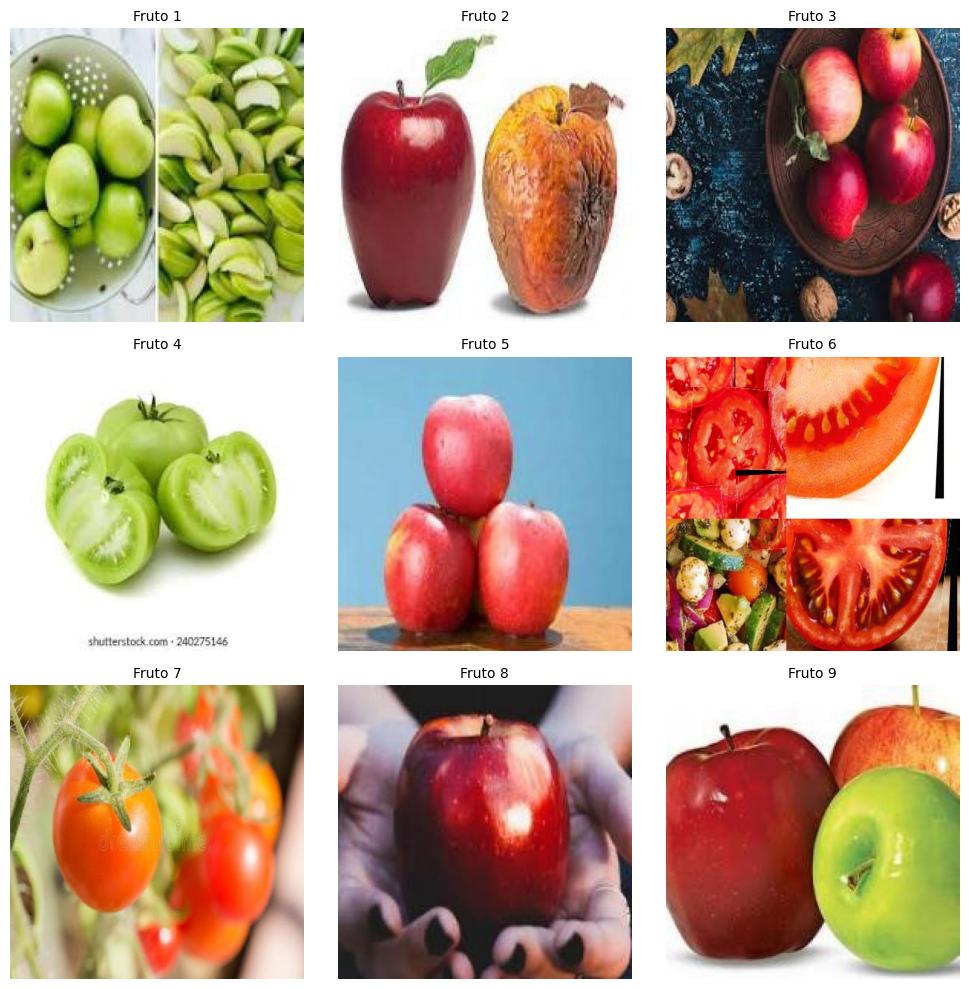

In [48]:
# visualizando o dataset roboflo
data_fruto = dataset

# Obtendo caminhos das imagens baixadas do Roboflow (pasta de treino)
pasta_imagens_yolo = os.path.join(dataset.location, 'train', 'images')
amostras_imagens = glob.glob(os.path.join(pasta_imagens_yolo, '*.jpg'))

# visualizando em plot
plt.figure(figsize=(10, 10))

# Plotando as 9 primeiras imagens se existirem
for i in range(min(9, len(amostras_imagens))):
    img_bgr = cv2.imread(amostras_imagens[i])
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img_rgb)
    plt.title(f"Fruto {i+1}", fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

---
# ETAPA FINAL — CORREÇÕES PARA ATENDER AO ROTEIRO

Esta seção consolida os itens obrigatórios. Execute em ordem depois de preparar o PlantVillage.
 A CNN final abaixo cria três subconjuntos estratificados independentes.


## 1. EDA e divisão estratificada treino / validação / teste

O dataframe será reconstruído diretamente das pastas do PlantVillage para que a execução não dependa de variáveis que existiam apenas em sessões anteriores do Colab.


Imagens: 20638
Classes: 15


,quantidade
classe,
Tomato__Tomato_YellowLeaf__Curl_Virus,3208
Tomato_Bacterial_spot,2127
Tomato_Late_blight,1909
Tomato_Septoria_leaf_spot,1771
Tomato_Spider_mites_Two_spotted_spider_mite,1676
Tomato_healthy,1591
Pepper__bell___healthy,1478
Tomato__Target_Spot,1404
Potato___Early_blight,1000


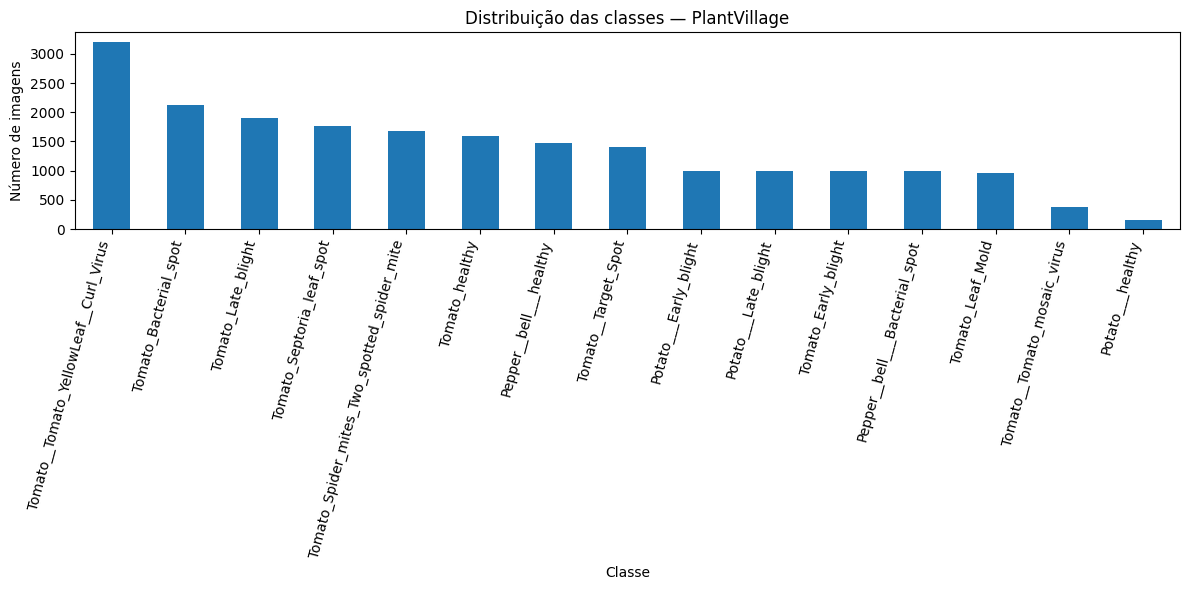

treino: 14446 imagens


,treino
classe,
Pepper__bell___Bacterial_spot,698
Pepper__bell___healthy,1035
Potato___Early_blight,700
Potato___Late_blight,700
Potato___healthy,106
Tomato_Bacterial_spot,1489
Tomato_Early_blight,700
Tomato_Late_blight,1336
Tomato_Leaf_Mold,666


validação: 3096 imagens


,validação
classe,
Pepper__bell___Bacterial_spot,150
Pepper__bell___healthy,222
Potato___Early_blight,150
Potato___Late_blight,150
Potato___healthy,23
Tomato_Bacterial_spot,319
Tomato_Early_blight,150
Tomato_Late_blight,286
Tomato_Leaf_Mold,143


teste: 3096 imagens


,teste
classe,
Pepper__bell___Bacterial_spot,149
Pepper__bell___healthy,221
Potato___Early_blight,150
Potato___Late_blight,150
Potato___healthy,23
Tomato_Bacterial_spot,319
Tomato_Early_blight,150
Tomato_Late_blight,287
Tomato_Leaf_Mold,143


Estrutura de diretórios criada em: /content/artifacts/PlantVillage_split


In [49]:
from pathlib import Path
import os, json, shutil, yaml, time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# caminho_encontrado é definido nas células iniciais do notebook.
ROOT_PLANTVILLAGE = Path(caminho_encontrado)
EXTENSOES = {".jpg", ".jpeg", ".png"}
registros = []
for pasta_classe in sorted(ROOT_PLANTVILLAGE.iterdir()):
    if pasta_classe.is_dir():
        for arquivo in pasta_classe.rglob("*"):
            if arquivo.suffix.lower() in EXTENSOES:
                registros.append({"caminho": str(arquivo), "classe": pasta_classe.name})

df_plantvillage_final = pd.DataFrame(registros)
if df_plantvillage_final.empty:
    raise RuntimeError(f"Nenhuma imagem foi localizada em {ROOT_PLANTVILLAGE}")


class_names_final = sorted(df_plantvillage_final["classe"].unique())
class_to_id_final = {name: idx for idx, name in enumerate(class_names_final)}
df_plantvillage_final["label"] = df_plantvillage_final["classe"].map(class_to_id_final)


print("Imagens:", len(df_plantvillage_final))
print("Classes:", len(class_names_final))
display(df_plantvillage_final["classe"].value_counts().rename("quantidade").to_frame())


plt.figure(figsize=(12, 6))
df_plantvillage_final["classe"].value_counts().plot(kind="bar")
plt.title("Distribuição das classes — PlantVillage")
plt.xlabel("Classe")
plt.ylabel("Número de imagens")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

# Divisão estratificada: 70% treino, 15% validação, 15% teste.
df_train_final, df_temp_final = train_test_split(
    df_plantvillage_final, test_size=0.30, random_state=42,
    stratify=df_plantvillage_final["label"]
)
df_val_final, df_test_final = train_test_split(
    df_temp_final, test_size=0.50, random_state=42,
    stratify=df_temp_final["label"]
)
for nome, parte in [("treino", df_train_final), ("validação", df_val_final), ("teste", df_test_final)]:
    print(f"{nome}: {len(parte)} imagens")
    display(parte["classe"].value_counts().sort_index().rename(nome).to_frame())

SPLIT_DIR = Path("artifacts/cnn_splits")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
df_train_final.to_csv(SPLIT_DIR / "train.csv", index=False)
df_val_final.to_csv(SPLIT_DIR / "validation.csv", index=False)
df_test_final.to_csv(SPLIT_DIR / "test.csv", index=False)



# Estrutura física treino/validação/teste sem duplicar os arquivos de imagem:
SPLIT_ROOT = Path("artifacts/PlantVillage_split")
for split_name, split_df in [
    ("train", df_train_final), ("val", df_val_final), ("test", df_test_final)
]:
    for row in split_df.itertuples(index=False):
        origem = Path(row.caminho)
        destino_dir = SPLIT_ROOT / split_name / row.classe
        destino_dir.mkdir(parents=True, exist_ok=True)
        destino = destino_dir / origem.name
        if not destino.exists():
            try:
                destino.symlink_to(origem.resolve())
            except OSError:
                # Fallback para ambientes que não permitem links simbólicos.
                shutil.copy2(origem, destino)


print("Estrutura de diretórios criada em:", SPLIT_ROOT.resolve())


## 2. Treinamento final da CNN e avaliação em teste independente

O modelo usa augmentation somente durante o treinamento. A validação orienta o treinamento; o teste fica separado até a avaliação final.


Epoch 1/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 66s 124ms/step - accuracy: 0.3534 - loss: 2.0239 - val_accuracy: 0.5969 - val_loss: 1.3517
Epoch 2/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 37s 41ms/step - accuracy: 0.5724 - loss: 1.3167 - val_accuracy: 0.6741 - val_loss: 0.9658
Epoch 3/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - accuracy: 0.6355 - loss: 1.0950 - val_accuracy: 0.7578 - val_loss: 0.7385
Epoch 4/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.6782 - loss: 0.9527 - val_accuracy: 0.8098 - val_loss: 0.5755
Epoch 5/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - accuracy: 0.7069 - loss: 0.8654 - val_accuracy: 0.7545 - val_loss: 0.7232
Epoch 6/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - accuracy: 0.7214 - loss: 0.8117 - val_accuracy: 0.7813 - val_loss: 0.6512
Epoch 7/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.7399 - loss: 0.7715 - val_accuracy: 0.8275 - val_loss: 0.5060
Epoch 8/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.7558 - loss: 0.7060 -

97/97 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step
RELATÓRIO FINAL — TESTE INDEPENDENTE
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.76      0.97      0.85       149
                     Pepper__bell___healthy       0.95      0.96      0.96       221
                      Potato___Early_blight       0.96      0.97      0.96       150
                       Potato___Late_blight       0.84      0.92      0.88       150
                           Potato___healthy       0.76      0.83      0.79        23
                      Tomato_Bacterial_spot       0.95      0.96      0.95       319
                        Tomato_Early_blight       0.74      0.77      0.75       150
                         Tomato_Late_blight       0.90      0.83      0.86       287
                           Tomato_Leaf_Mold       0.94      0.83      0.88       143
                  Tomato_Septoria_leaf_spot       0.88      0.87      0.

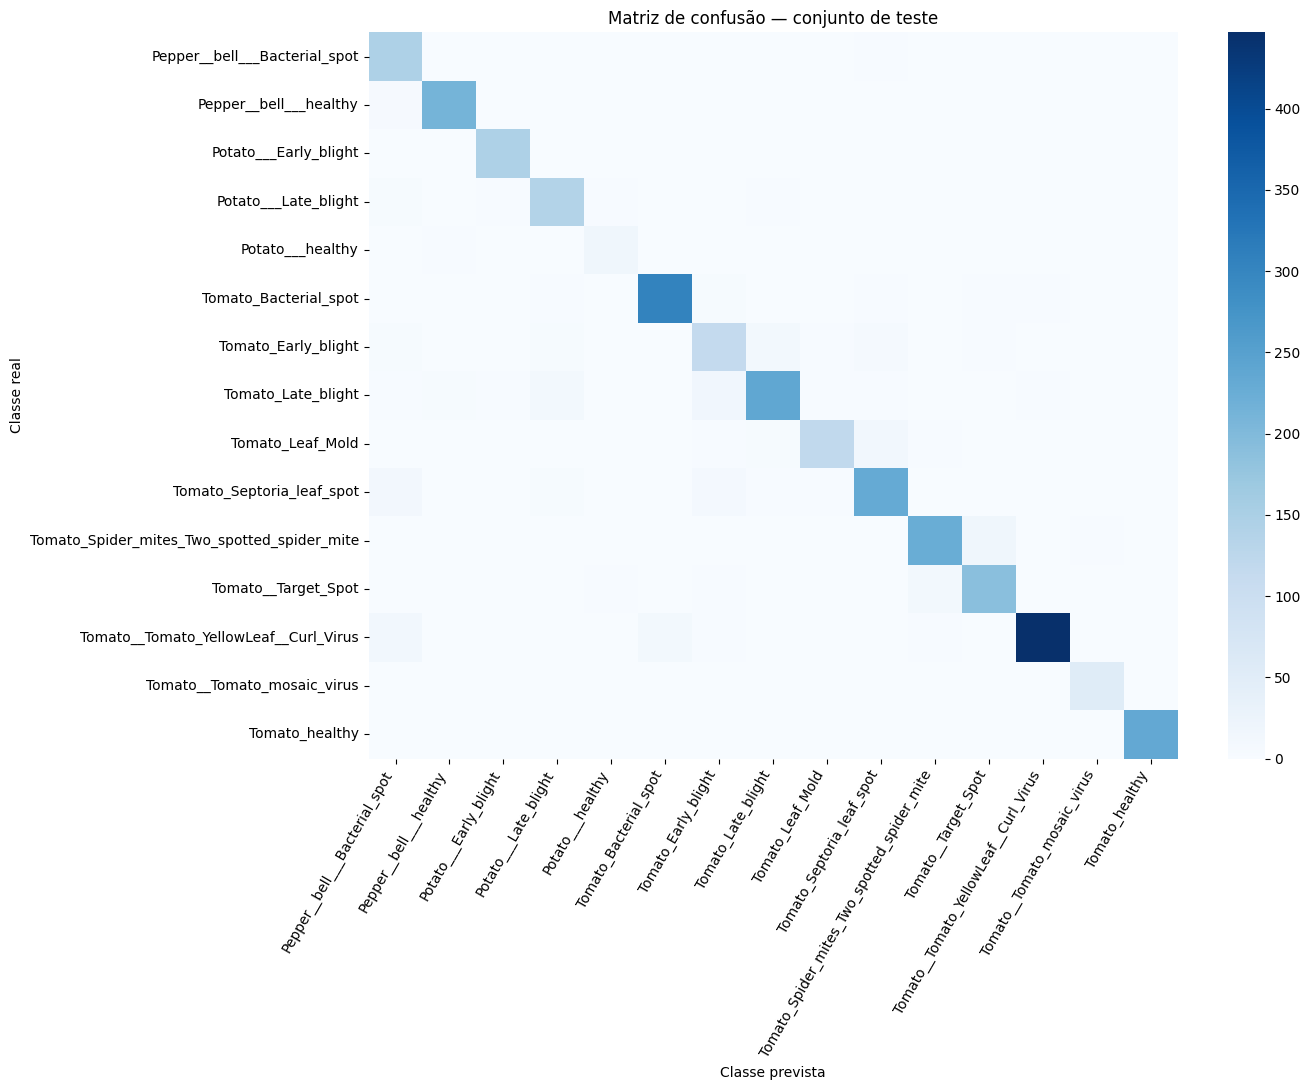

Artefatos CNN salvos em models/ e results/.


In [52]:
IMG_SIZE_FINAL = (128, 128)
BATCH_FINAL = 32
AUTOTUNE = tf.data.AUTOTUNE
RUN_CNN_FINAL = True  # Caso eu precise de False apenas se já tiver gerado os artefatos finais.


def carregar_imagem_cnn(caminho, label):
    conteudo = tf.io.read_file(caminho)
    imagem = tf.io.decode_image(conteudo, channels=3, expand_animations=False)
    imagem.set_shape([None, None, 3])
    imagem = tf.image.resize(imagem, IMG_SIZE_FINAL)
    imagem = tf.cast(imagem, tf.float32) / 255.0
    return imagem, tf.cast(label, tf.int32)



def criar_dataset_cnn(df, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((
        df["caminho"].astype(str).values,
        df["label"].astype("int32").values
    ))
    if shuffle:
        ds = ds.shuffle(min(len(df), 10000), seed=42, reshuffle_each_iteration=True)
    return ds.map(carregar_imagem_cnn, num_parallel_calls=AUTOTUNE).batch(BATCH_FINAL).prefetch(AUTOTUNE)

train_ds_final = criar_dataset_cnn(df_train_final, shuffle=True)
val_ds_final = criar_dataset_cnn(df_val_final)
test_ds_final = criar_dataset_cnn(df_test_final)

if RUN_CNN_FINAL:
    augmentation_final = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.12),
        tf.keras.layers.RandomZoom(0.10),
        tf.keras.layers.RandomContrast(0.10),
    ], name="data_augmentation")



    cnn_final = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(128, 128, 3)),
        augmentation_final,
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.40),
        tf.keras.layers.Dense(len(class_names_final), activation="softmax")
    ])
    cnn_final.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )



    pesos_classes = compute_class_weight(
        class_weight="balanced",
        classes=np.unique(df_train_final["label"]),
        y=df_train_final["label"]
    )


    class_weight_final = {i: float(w) for i, w in enumerate(pesos_classes)}

    callbacks_final = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(
            "artifacts/modelo_folhas_checkpoint.keras",
            monitor="val_loss", save_best_only=True
        )
    ]
    history_final = cnn_final.fit(
        train_ds_final, validation_data=val_ds_final,
        epochs=15, class_weight=class_weight_final,
        callbacks=callbacks_final
    )

    # Métricas finais somente no conjunto de teste nunca usado no ajuste.
    y_test_final = np.concatenate([y.numpy() for _, y in test_ds_final])
    prob_test_final = cnn_final.predict(test_ds_final, verbose=1)
    pred_test_final = np.argmax(prob_test_final, axis=1)

    print("RELATÓRIO FINAL — TESTE INDEPENDENTE")
    print(classification_report(
        y_test_final, pred_test_final,
        labels=np.arange(len(class_names_final)),
        target_names=class_names_final,
        zero_division=0
    ))

    cm_final = confusion_matrix(
        y_test_final, pred_test_final, labels=np.arange(len(class_names_final))
    )
    plt.figure(figsize=(14, 11))
    sns.heatmap(cm_final, cmap="Blues", xticklabels=class_names_final, yticklabels=class_names_final)
    plt.title("Matriz de confusão — conjunto de teste")
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe real")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.savefig("artifacts/matriz_confusao_cnn_teste.png", dpi=160)
    plt.show()

    os.makedirs("models", exist_ok=True)
    cnn_final.save("models/modelo_folhas.keras")
    with open("models/classes.json", "w", encoding="utf-8") as f:
        json.dump(class_names_final, f, ensure_ascii=False, indent=2)

    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
    metricas_cnn = {
        "accuracy": float(accuracy_score(y_test_final, pred_test_final)),
        "precision_macro": float(precision_score(y_test_final, pred_test_final, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_test_final, pred_test_final, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_test_final, pred_test_final, average="macro", zero_division=0)),
        "n_test": int(len(y_test_final)),
        "classes": class_names_final
    }
    Path("results").mkdir(exist_ok=True)
    with open("results/metricas_cnn_teste.json", "w", encoding="utf-8") as f:
        json.dump(metricas_cnn, f, ensure_ascii=False, indent=2)
    print("Artefatos CNN salvos em models/ e results/.")
else:
    cnn_final = tf.keras.models.load_model("models/modelo_folhas.keras")
    class_names_final = json.loads(Path("models/classes.json").read_text(encoding="utf-8"))


## 3. YOLOv8, YOLOv9 e YOLOv11 — detecção de frutos


In [53]:
from pathlib import Path
import os, json, shutil, yaml, torch
from ultralytics import YOLO

# Se a célula de download do Roboflow acima foi executada, `dataset.location` já existe.
if "dataset" not in globals():
    raise RuntimeError("Baixe o dataset de frutos na célula Roboflow antes de treinar os detectores.")

FRUIT_DATASET_DIR = Path(dataset.location)
FRUIT_YAML = FRUIT_DATASET_DIR / "data.yaml"
if not FRUIT_YAML.exists():
    candidatos = list(FRUIT_DATASET_DIR.rglob("data.yaml"))
    if not candidatos:
        raise FileNotFoundError(f"data.yaml não encontrado dentro de {FRUIT_DATASET_DIR}")
    FRUIT_YAML = candidatos[0]




cfg = yaml.safe_load(FRUIT_YAML.read_text(encoding="utf-8"))

if not cfg.get("train") or not cfg.get("val") or not cfg.get("names"):
    raise ValueError("data.yaml precisa declarar train, val e names.")
print("Dataset de frutos:", FRUIT_DATASET_DIR)
print("Classes:", cfg["names"])
print("CUDA disponível:", torch.cuda.is_available())

# Modelos oficiais pré-treinados usados como ponto de partida (fine-tuning).
YOLO_CONFIGS = {
    "v8": "yolov8n.pt",
    "v9": "yolov9t.pt",
    "v11": "yolo11n.pt",
}


RUN_YOLO_TRAINING = True
YOLO_EPOCHS = 17
YOLO_IMAGE_SIZE = 640
YOLO_BATCH = 16 if torch.cuda.is_available() else 8
YOLO_DEVICE = 0 if torch.cuda.is_available() else "cpu"

Path("models").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)
resultados_comparacao = []

if RUN_YOLO_TRAINING:
    for versao, peso_base in YOLO_CONFIGS.items():
        print(f"\\n===== Fine-tuning {versao.upper()} ({peso_base}) =====")
        detector = YOLO(peso_base)
        treino = detector.train(
            data=str(FRUIT_YAML),
            epochs=YOLO_EPOCHS,
            imgsz=YOLO_IMAGE_SIZE,
            batch=YOLO_BATCH,
            device=YOLO_DEVICE,
            patience=10,
            project="AgroVisionAI_YOLO",
            name=f"frutos_{versao}",
            exist_ok=True,
            plots=True,
            save=True,
            workers=2,
            seed=42
        )


        best_pt = Path(treino.save_dir) / "weights" / "best.pt"
        if not best_pt.exists():
            raise FileNotFoundError(f"best.pt não foi criado para {versao}: {best_pt}")

        destino = Path("models") / {
            "v8": "yolov8_best.pt",
            "v9": "yolov9_best.pt",
            "v11": "yolo11_best.pt"
        }[versao]
        shutil.copy2(best_pt, destino)

        # Avaliação em test, se disponível; caso contrário, val (declarar isso no relatório).
        split_avaliacao = "test" if cfg.get("test") else "val"
        detector_final = YOLO(str(destino))
        metricas = detector_final.val(
            data=str(FRUIT_YAML),
            split=split_avaliacao,
            imgsz=YOLO_IMAGE_SIZE,
            batch=YOLO_BATCH,
            device=YOLO_DEVICE,
            plots=True
        )


        box_metrics = metricas.box
        resultados_comparacao.append({
            "modelo": versao,
            "peso": str(destino),
            "split_avaliacao": split_avaliacao,
            "precision": float(box_metrics.mp),
            "recall": float(box_metrics.mr),
            "mAP50": float(box_metrics.map50),
            "mAP50_95": float(box_metrics.map),
        })

df_yolo_comparacao = pd.DataFrame(resultados_comparacao)
if not df_yolo_comparacao.empty:
    display(df_yolo_comparacao)
    df_yolo_comparacao.to_csv("results/comparacao_yolo_frutos.csv", index=False)
    df_yolo_comparacao.to_json("results/comparacao_yolo_frutos.json", orient="records", indent=2)
else:
    print("Treinamento não executado. Não existem métricas YOLO finais para reportar.")




print("Pesos presentes:", [p.name for p in Path("models").glob("*.pt")])


Dataset de frutos: /content/Apple-and-Tomato-Detection1-1
Classes: {0: 'Tomato', 1: 'apple'}
CUDA disponível: True
\n===== Fine-tuning V8 (yolov8n.pt) =====
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Apple-and-Tomato-Detection1-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=17, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, ma

,modelo,peso,split_avaliacao,precision,recall,mAP50,mAP50_95
0,v8,models/yolov8_best.pt,test,0.851352,0.784329,0.893245,0.580244
1,v9,models/yolov9_best.pt,test,0.847705,0.858392,0.935053,0.609652
2,v11,models/yolo11_best.pt,test,0.832932,0.867557,0.911334,0.591457


Pesos presentes: ['yolov9_best.pt', 'yolo11_best.pt', 'yolov8_best.pt']


## 4. Análise de bounding boxes, falsos positivos e falsos negativos

- **Falso positivo:** o modelo desenha uma caixa sobre algo que não é fruto.
- **Falso negativo:** existe fruto anotado na imagem, mas o modelo não o detecta.
- **Bounding box inadequada:** a caixa detecta o fruto, mas está deslocada ou cobre área excessiva.



In [57]:
# Visualização qualitativa de detecções com o melhor peso disponível.
from IPython.display import display, Image as IPyImage

pesos_disponiveis = {
    "v8": Path("models/yolov8_best.pt"),
    "v9": Path("models/yolov9_best.pt"),
    "v11": Path("models/yolo11_best.pt"),
}
for versao, peso in pesos_disponiveis.items():
    if peso.exists():
        modelo_vis = YOLO(str(peso))
        amostras = list((FRUIT_DATASET_DIR / "test" / "images").glob("*")) if (FRUIT_DATASET_DIR / "test" / "images").exists() else list((FRUIT_DATASET_DIR / "valid" / "images").glob("*"))
        if amostras:
            pred = modelo_vis.predict(source=str(amostras[0]), conf=0.25, save=True, project="results/visualizacoes", name=versao, exist_ok=True)
            print(f"{versao}: imagem processada; confira results/visualizacoes/{versao}")
        else:
            print(f"{versao}: pasta de imagens test/valid não localizada para visualização.")
    else:
        print(f"{versao}: peso ausente; execute o treinamento.")



image 1/1 /content/Apple-and-Tomato-Detection1-1/test/images/damaged_apple-73-_jpg.rf.f3bb43a6cfd5e900eb03dc202294939c.jpg: 640x640 1 apple, 7.7ms
Speed: 2.7ms preprocess, 7.7ms inference, 2.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/results/visualizacoes/v8
v8: imagem processada; confira results/visualizacoes/v8

image 1/1 /content/Apple-and-Tomato-Detection1-1/test/images/damaged_apple-73-_jpg.rf.f3bb43a6cfd5e900eb03dc202294939c.jpg: 640x640 1 apple, 16.5ms
Speed: 1.0ms preprocess, 16.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/results/visualizacoes/v9
v9: imagem processada; confira results/visualizacoes/v9

image 1/1 /content/Apple-and-Tomato-Detection1-1/test/images/damaged_apple-73-_jpg.rf.f3bb43a6cfd5e900eb03dc202294939c.jpg: 640x640 1 apple, 8.7ms
Speed: 1.4ms preprocess, 8.7ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/ru

## 5. Gerar API FastAPI final e coleção Postman

A API carrega os modelos uma vez na inicialização. Se um peso YOLO ainda não existir, a rota daquela versão responde HTTP 503; ela nunca usa um peso genérico como se fosse um modelo treinado no dataset de frutos.


In [54]:
from pathlib import Path
import json

API_CODE = '"""\nAgroVisionAI - API REST\nEndpoints:\n  POST /classificar-folha\n  POST /detectar-fruto?modelo=v8|v9|v11\n  GET  /health\nOs pesos devem estar em ./models/ e o modelo CNN em ./models/modelo_folhas.keras.\n"""\nimport json\nimport os\nfrom contextlib import asynccontextmanager\nfrom pathlib import Path\nfrom typing import Dict\n\nimport cv2\nimport numpy as np\nimport tensorflow as tf\nfrom fastapi import FastAPI, File, HTTPException, Query, UploadFile\nfrom fastapi.responses import JSONResponse\nfrom ultralytics import YOLO\n\nBASE_DIR = Path(__file__).resolve().parent\nMODELS_DIR = Path(os.getenv("AGROVISION_MODELS_DIR", BASE_DIR / "models"))\nCNN_PATH = Path(os.getenv("AGROVISION_CNN_PATH", MODELS_DIR / "modelo_folhas.keras"))\nCLASSES_PATH = Path(os.getenv("AGROVISION_CLASSES_PATH", MODELS_DIR / "classes.json"))\nMAX_IMAGE_BYTES = int(os.getenv("MAX_IMAGE_BYTES", 10 * 1024 * 1024))\n\nYOLO_FILES = {\n    "v8": Path(os.getenv("YOLO_V8_WEIGHTS", MODELS_DIR / "yolov8_best.pt")),\n    "v9": Path(os.getenv("YOLO_V9_WEIGHTS", MODELS_DIR / "yolov9_best.pt")),\n    "v11": Path(os.getenv("YOLO_V11_WEIGHTS", MODELS_DIR / "yolo11_best.pt")),\n}\n\nstate: Dict = {"cnn": None, "classes": [], "yolo": {}, "load_errors": {}}\n\n\ndef load_artifacts():\n    state["load_errors"] = {}\n    if CNN_PATH.exists() and CLASSES_PATH.exists():\n        try:\n            state["cnn"] = tf.keras.models.load_model(CNN_PATH)\n            state["classes"] = json.loads(CLASSES_PATH.read_text(encoding="utf-8"))\n        except Exception as exc:\n            state["load_errors"]["cnn"] = str(exc)\n            state["cnn"] = None\n    else:\n        state["load_errors"]["cnn"] = (\n            f"Arquivos ausentes: {CNN_PATH.name} e/ou {CLASSES_PATH.name}"\n        )\n\n    state["yolo"] = {}\n    for version, weights_path in YOLO_FILES.items():\n        if weights_path.exists():\n            try:\n                state["yolo"][version] = YOLO(str(weights_path))\n            except Exception as exc:\n                state["load_errors"][f"yolo_{version}"] = str(exc)\n        else:\n            state["load_errors"][f"yolo_{version}"] = f"Pesos não encontrados: {weights_path}"\n\n\n@asynccontextmanager\nasync def lifespan(app: FastAPI):\n    load_artifacts()\n    yield\n\n\napp = FastAPI(\n    title="AgroVisionAI",\n    description="API REST para classificação de folhas e detecção de frutos.",\n    version="2.0.0",\n    lifespan=lifespan,\n)\n\n\nasync def read_image(file: UploadFile) -> np.ndarray:\n    allowed = {"image/jpeg", "image/png", "image/jpg"}\n    if file.content_type and file.content_type.lower() not in allowed:\n        raise HTTPException(status_code=415, detail="Envie uma imagem PNG ou JPEG.")\n    content = await file.read()\n    if not content:\n        raise HTTPException(status_code=400, detail="Arquivo vazio.")\n    if len(content) > MAX_IMAGE_BYTES:\n        raise HTTPException(status_code=413, detail="Imagem excede o limite de 10 MB.")\n    image = cv2.imdecode(np.frombuffer(content, dtype=np.uint8), cv2.IMREAD_COLOR)\n    if image is None:\n        raise HTTPException(status_code=400, detail="Não foi possível decodificar a imagem.")\n    return image\n\n\n@app.get("/health")\nasync def health():\n    return {\n        "status": "healthy",\n        "cnn_loaded": state["cnn"] is not None,\n        "classes_loaded": len(state["classes"]) > 0,\n        "yolo_loaded": sorted(state["yolo"].keys()),\n        "load_errors": state["load_errors"],\n    }\n\n\n@app.post("/classificar-folha")\nasync def classificar_folha(file: UploadFile = File(...)):\n    if state["cnn"] is None:\n        raise HTTPException(\n            status_code=503,\n            detail="CNN indisponível. Treine/exporte o modelo e coloque modelo_folhas.keras e classes.json em models/.",\n        )\n    image_bgr = await read_image(file)\n    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)\n    input_shape = state["cnn"].input_shape\n    height = int(input_shape[1] or 128)\n    width = int(input_shape[2] or 128)\n    resized = cv2.resize(image_rgb, (width, height)).astype("float32") / 255.0\n    probabilities = state["cnn"].predict(np.expand_dims(resized, axis=0), verbose=0)[0]\n    class_index = int(np.argmax(probabilities))\n    if class_index >= len(state["classes"]):\n        raise HTTPException(status_code=500, detail="Mapeamento de classes incompatível com a CNN.")\n    confidence = float(probabilities[class_index])\n    class_name = state["classes"][class_index]\n    healthy = "healthy" in class_name.lower()\n    return {\n        "arquivo": file.filename,\n        "classe_id": class_index,\n        "classe": class_name,\n        "condicao": "saudavel" if healthy else "possivel_doenca",\n        "confianca": round(confidence, 6),\n        "observacao": "Predição automatizada; confirme o diagnóstico com avaliação agronômica.",\n    }\n\n\n@app.post("/detectar-fruto")\nasync def detectar_fruto(\n    file: UploadFile = File(...),\n    modelo: str = Query("v8", pattern="^(v8|v9|v11)$"),\n    confianca_minima: float = Query(0.25, ge=0.0, le=1.0),\n):\n    detector = state["yolo"].get(modelo)\n    if detector is None:\n        raise HTTPException(\n            status_code=503,\n            detail=f"Modelo {modelo} não carregado. Verifique se o peso correspondente está em {MODELS_DIR}.",\n        )\n    image_bgr = await read_image(file)\n    results = detector.predict(source=image_bgr, conf=confianca_minima, verbose=False)\n    detections = []\n    if results and results[0].boxes is not None:\n        for box in results[0].boxes:\n            x1, y1, x2, y2 = [float(v) for v in box.xyxy[0].cpu().tolist()]\n            class_id = int(box.cls[0].item())\n            detections.append({\n                "classe_id": class_id,\n                "classe": detector.names.get(class_id, str(class_id)),\n                "confianca": round(float(box.conf[0].item()), 6),\n                "bbox": {\n                    "x1": round(x1, 2), "y1": round(y1, 2),\n                    "x2": round(x2, 2), "y2": round(y2, 2),\n                },\n            })\n    return {\n        "arquivo": file.filename,\n        "modelo": modelo,\n        "total_deteccoes": len(detections),\n        "deteccoes": detections,\n    }\n\n\n@app.exception_handler(Exception)\nasync def unexpected_error_handler(request, exc):\n    # Erros HTTP previstos continuam sendo tratados pelo FastAPI.\n    if isinstance(exc, HTTPException):\n        return JSONResponse(status_code=exc.status_code, content={"detail": exc.detail})\n    return JSONResponse(status_code=500, content={"detail": "Erro interno ao processar a requisição."})\n'
Path("api.py").write_text(API_CODE, encoding="utf-8")
print("api.py final criado.")


api.py final criado.


In [55]:
POSTMAN_COLLECTION = '{\n  "info": {\n    "_postman_id": "d4b50c6e-4a55-4b3d-8c61-5f91f09f33a2",\n    "name": "AgroVisionAI - API REST",\n    "description": "Testes dos endpoints de classificação de folhas e detecção de frutos.",\n    "schema": "https://schema.getpostman.com/json/collection/v2.1.0/collection.json"\n  },\n  "variable": [\n    {\n      "key": "base_url",\n      "value": "http://127.0.0.1:8000"\n    },\n    {\n      "key": "modelo",\n      "value": "v8"\n    }\n  ],\n  "item": [\n    {\n      "name": "Health Check",\n      "request": {\n        "method": "GET",\n        "header": [],\n        "url": {\n          "raw": "{{base_url}}/health",\n          "host": [\n            "{{base_url}}"\n          ],\n          "path": [\n            "health"\n          ]\n        }\n      },\n      "event": [\n        {\n          "listen": "test",\n          "script": {\n            "type": "text/javascript",\n            "exec": [\n              "pm.test(\'HTTP 200\', () => pm.response.to.have.status(200));",\n              "pm.test(\'status healthy\', () => pm.expect(pm.response.json().status).to.eql(\'healthy\'));"\n            ]\n          }\n        }\n      ]\n    },\n    {\n      "name": "Classificar folha",\n      "request": {\n        "method": "POST",\n        "header": [],\n        "body": {\n          "mode": "formdata",\n          "formdata": [\n            {\n              "key": "file",\n              "type": "file",\n              "src": ""\n            }\n          ]\n        },\n        "url": {\n          "raw": "{{base_url}}/classificar-folha",\n          "host": [\n            "{{base_url}}"\n          ],\n          "path": [\n            "classificar-folha"\n          ]\n        }\n      },\n      "event": [\n        {\n          "listen": "test",\n          "script": {\n            "type": "text/javascript",\n            "exec": [\n              "pm.test(\'HTTP 200\', () => pm.response.to.have.status(200));",\n              "pm.test(\'retorna classe e confiança\', () => { const d=pm.response.json(); pm.expect(d).to.have.property(\'classe\'); pm.expect(d.confianca).to.be.a(\'number\'); });"\n            ]\n          }\n        }\n      ]\n    },\n    {\n      "name": "Detectar frutos - modelo selecionável",\n      "request": {\n        "method": "POST",\n        "header": [],\n        "body": {\n          "mode": "formdata",\n          "formdata": [\n            {\n              "key": "file",\n              "type": "file",\n              "src": ""\n            }\n          ]\n        },\n        "url": {\n          "raw": "{{base_url}}/detectar-fruto?modelo={{modelo}}",\n          "host": [\n            "{{base_url}}"\n          ],\n          "path": [\n            "detectar-fruto"\n          ],\n          "query": [\n            {\n              "key": "modelo",\n              "value": "{{modelo}}"\n            }\n          ]\n        }\n      },\n      "event": [\n        {\n          "listen": "test",\n          "script": {\n            "type": "text/javascript",\n            "exec": [\n              "pm.test(\'HTTP 200\', () => pm.response.to.have.status(200));",\n              "pm.test(\'retorna lista de detecções\', () => { const d=pm.response.json(); pm.expect(d).to.have.property(\'deteccoes\'); pm.expect(d.deteccoes).to.be.an(\'array\'); });"\n            ]\n          }\n        }\n      ]\n    }\n  ]\n}'
Path("AgroVisionAI_Postman_Collection.json").write_text(POSTMAN_COLLECTION, encoding="utf-8")
print("AgroVisionAI_Postman_Collection.json criado.")


AgroVisionAI_Postman_Collection.json criado.


## 6. Executar e testar a API

No Colab, execute o servidor em uma célula separada (ou abra um terminal local). Para a entrega local, coloque `api.py`, `requirements.txt` e a pasta `models/` no mesmo diretório.


In [56]:
# Instalação (Colab ou ambiente virtual local)
# !pip install -r requirements.txt

# Inicie em um terminal:
# uvicorn api:app --host 0.0.0.0 --port 8000 --reload
#
# Swagger: http://127.0.0.1:8000/docs
# Health:  http://127.0.0.1:8000/health
#
# Postman:
# 1. Importe AgroVisionAI_Postman_Collection.json.
# 2. Em cada requisição POST, selecione uma imagem no campo form-data "file".
# 3. Para detectar frutos, altere a variável collection "modelo" para v8, v9 e v11.
# 4. Guarde capturas das respostas HTTP 200 e dos JSON retornados.



**Limitação do PlantVillage:** imagens controladas, fundo relativamente uniforme e condições de captura pouco variadas. O desempenho em campo pode cair com iluminação variável, sombras, folhas parcialmente oclusas, diferentes câmeras, estágios de doença e fundos complexos. O modelo é apoio à triagem, não substitui diagnóstico agronômico.
